In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not available")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
!pip install -q segmentation-models-pytorch albumentations kaggle openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.4 MB/s eta 0:00:00


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

import segmentation_models_pytorch as smp

from sklearn.metrics import confusion_matrix

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!mkdir -p /content/amd_dataset

!kaggle datasets download \
    -d gaoweihao/amd-sd \
    -p /content/amd_dataset

Dataset URL: https://www.kaggle.com/datasets/gaoweihao/amd-sd
License(s): CC0-1.0
100% 819M/819M [00:10<00:00, 80.9MB/s]



In [ ]:
!unzip -q /content/amd_dataset/amd-sd.zip \
    -d /content/amd_dataset

In [ ]:
!find /content/amd_dataset -maxdepth 3 -type f | head -50

/content/amd_dataset/masks/75_16.png
/content/amd_dataset/masks/50_20.png
/content/amd_dataset/masks/144_14.png
/content/amd_dataset/masks/143_15.png
/content/amd_dataset/masks/130_4.png
/content/amd_dataset/masks/104_4.png
/content/amd_dataset/masks/71_20.png
/content/amd_dataset/masks/150_11.png
/content/amd_dataset/masks/87_14.png
/content/amd_dataset/masks/105_28.png
/content/amd_dataset/masks/48_6.png
/content/amd_dataset/masks/69_18.png
/content/amd_dataset/masks/55_8.png
/content/amd_dataset/masks/131_18.png
/content/amd_dataset/masks/137_18.png
/content/amd_dataset/masks/39_7.png
/content/amd_dataset/masks/16_1.png
/content/amd_dataset/masks/5_9.png
/content/amd_dataset/masks/106_31.png
/content/amd_dataset/masks/65_15.png
/content/amd_dataset/masks/27_11.png
/content/amd_dataset/masks/92_9.png
/content/amd_dataset/masks/60_23.png
/content/amd_dataset/masks/148_2.png
/content/amd_dataset/masks/47_17.png
/content/amd_dataset/masks/78_13.png
/content/amd_dataset/masks/142_9.png
/

In [ ]:
import os

for root, dirs, files in os.walk("/content/amd_dataset"):
    if "training.txt" in files or "validation.txt" in files:
        print("Dataset folder found:")
        print(root)

In [ ]:
DATASET_DIR = '/content/amd_dataset'
print("Dataset contents:\n")

for item in os.listdir(DATASET_DIR):
    print(item)

Dataset contents:

masks
amd-sd.zip
images


In [ ]:
image_dir = os.path.join(DATASET_DIR, 'images')
mask_dir = os.path.join(DATASET_DIR, 'masks')

if os.path.exists(image_dir):
    all_images = sorted(os.listdir(image_dir))
    all_masks = sorted(os.listdir(mask_dir))
    print(f"Total images found: {len(all_images)}")
    print(f"Total masks found: {len(all_masks)}")
    print("First 5 images:", all_images[:5])
    print("First 5 masks:", all_masks[:5])
else:
    print("Images directory not found.")

Total images found: 3049
Total masks found: 3049
First 5 images: ['100_1.png', '100_10.png', '100_11.png', '100_12.png', '100_13.png']
First 5 masks: ['100_1.png', '100_10.png', '100_11.png', '100_12.png', '100_13.png']


In [ ]:
# Correct AMD-SD color mapping

COLOR_TO_CLASS = {

    (0, 0, 0): 0,        # Background

    (0, 0, 255): 1,     # SRF - Blue

    (255, 0, 0): 2,     # PED - Red

    (0, 255, 0): 3,     # IRF - Green

    (255, 255, 0): 4,   # SHRM - Yellow

    (0, 255, 255): 5    # IS/OS - Cyan
}

CLASS_NAMES = [
    "Background",
    "SRF",
    "PED",
    "IRF",
    "SHRM",
    "IS/OS"
]

NUM_CLASSES = 6

print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASS_NAMES)

Number of classes: 6
Classes: ['Background', 'SRF', 'PED', 'IRF', 'SHRM', 'IS/OS']


In [ ]:
image_files = []

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith(".png"):
            image_files.append(os.path.join(root, file))

print("Total PNG files:", len(image_files))
print(image_files[:10])

Total PNG files: 6098
['/content/amd_dataset/masks/75_16.png', '/content/amd_dataset/masks/50_20.png', '/content/amd_dataset/masks/144_14.png', '/content/amd_dataset/masks/143_15.png', '/content/amd_dataset/masks/130_4.png', '/content/amd_dataset/masks/104_4.png', '/content/amd_dataset/masks/71_20.png', '/content/amd_dataset/masks/150_11.png', '/content/amd_dataset/masks/87_14.png', '/content/amd_dataset/masks/105_28.png']


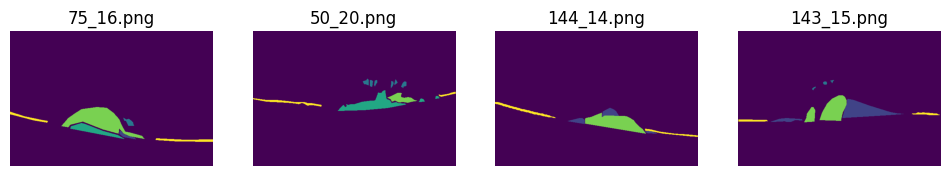

In [ ]:
plt.figure(figsize=(12, 5))

for i, path in enumerate(image_files[:4]):

    img = Image.open(path)

    plt.subplot(1, 4, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(path))
    plt.axis("off")

plt.show()

In [ ]:
for path in image_files[:20]:
    img = np.array(Image.open(path).convert("RGB"))

    unique_colors = np.unique(
        img.reshape(-1, 3),
        axis=0
    )

    print(os.path.basename(path),
          "shape =", img.shape,
          "unique colors =", len(unique_colors))

75_16.png shape = (380, 570, 3) unique colors = 6
50_20.png shape = (380, 570, 3) unique colors = 5
144_14.png shape = (380, 570, 3) unique colors = 4
143_15.png shape = (380, 570, 3) unique colors = 5
130_4.png shape = (380, 570, 3) unique colors = 4
104_4.png shape = (380, 570, 3) unique colors = 2
71_20.png shape = (380, 570, 3) unique colors = 3
150_11.png shape = (380, 570, 3) unique colors = 3
87_14.png shape = (380, 570, 3) unique colors = 5
105_28.png shape = (380, 570, 3) unique colors = 4
48_6.png shape = (380, 570, 3) unique colors = 5
69_18.png shape = (380, 570, 3) unique colors = 5
55_8.png shape = (380, 570, 3) unique colors = 5
131_18.png shape = (380, 570, 3) unique colors = 3
137_18.png shape = (380, 570, 3) unique colors = 5
39_7.png shape = (380, 570, 3) unique colors = 4
16_1.png shape = (380, 570, 3) unique colors = 2
5_9.png shape = (380, 570, 3) unique colors = 5
106_31.png shape = (380, 570, 3) unique colors = 2
65_15.png shape = (380, 570, 3) unique colors = 3

In [ ]:
def is_mask_image(path):

    img = np.array(Image.open(path).convert("RGB"))

    colors = set(map(tuple, img.reshape(-1, 3)))

    mask_colors = set(CLASS_COLORS.values())

    overlap = colors.intersection(mask_colors)

    return len(overlap) >= 2

In [ ]:
import os

print("Dataset directory:", DATASET_DIR)

for root, dirs, files in os.walk(DATASET_DIR):
    print("\nFOLDER:", root)
    print("Number of files:", len(files))
    print("Sample files:", files[:10])

Dataset directory: /content/amd_dataset

FOLDER: /content/amd_dataset
Number of files: 1
Sample files: ['amd-sd.zip']

FOLDER: /content/amd_dataset/masks
Number of files: 3049
Sample files: ['75_16.png', '50_20.png', '144_14.png', '143_15.png', '130_4.png', '104_4.png', '71_20.png', '150_11.png', '87_14.png', '105_28.png']

FOLDER: /content/amd_dataset/images
Number of files: 3049
Sample files: ['75_16.png', '50_20.png', '144_14.png', '143_15.png', '130_4.png', '104_4.png', '71_20.png', '150_11.png', '87_14.png', '105_28.png']


In [ ]:
import os

DATASET_DIR = "/content/amd_dataset"

IMAGE_DIR = os.path.join(DATASET_DIR, "images")
MASK_DIR = os.path.join(DATASET_DIR, "masks")

print("Images folder exists:", os.path.exists(IMAGE_DIR))
print("Masks folder exists:", os.path.exists(MASK_DIR))

image_files = [
    os.path.join(IMAGE_DIR, f)
    for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

mask_files = [
    os.path.join(MASK_DIR, f)
    for f in os.listdir(MASK_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

print("OCT images:", len(image_files))
print("Mask images:", len(mask_files))

Images folder exists: True
Masks folder exists: True
OCT images: 3049
Mask images: 3049


In [ ]:
print("OCT examples:")
for f in image_files[:10]:
    print(os.path.basename(f))

print("\nMASK examples:")
for f in mask_files[:10]:
    print(os.path.basename(f))

OCT examples:
75_16.png
50_20.png
144_14.png
143_15.png
130_4.png
104_4.png
71_20.png
150_11.png
87_14.png
105_28.png

MASK examples:
75_16.png
50_20.png
144_14.png
143_15.png
130_4.png
104_4.png
71_20.png
150_11.png
87_14.png
105_28.png


In [ ]:
mask_dict = {
    os.path.basename(path): path
    for path in mask_files
}

pairs = []

for img_path in image_files:

    name = os.path.basename(img_path)

    if name in mask_dict:
        pairs.append((img_path, mask_dict[name]))

print("Matched pairs:", len(pairs))

Matched pairs: 3049


In [ ]:
def rgb_to_mask(mask_rgb):

    h, w, _ = mask_rgb.shape

    mask = np.zeros((h, w), dtype=np.uint8)

    for class_id, color in CLASS_COLORS.items():

        match = np.all(mask_rgb == color, axis=-1)

        mask[match] = class_id

    return mask

In [ ]:
sample_img_path, sample_mask_path = pairs[0]

sample_img = np.array(
    Image.open(sample_img_path).convert("RGB")
)

sample_mask = np.array(
    Image.open(sample_mask_path).convert("RGB")
)

print("Image shape:", sample_img.shape)
print("Mask shape:", sample_mask.shape)

Image shape: (380, 570, 3)
Mask shape: (380, 570, 3)


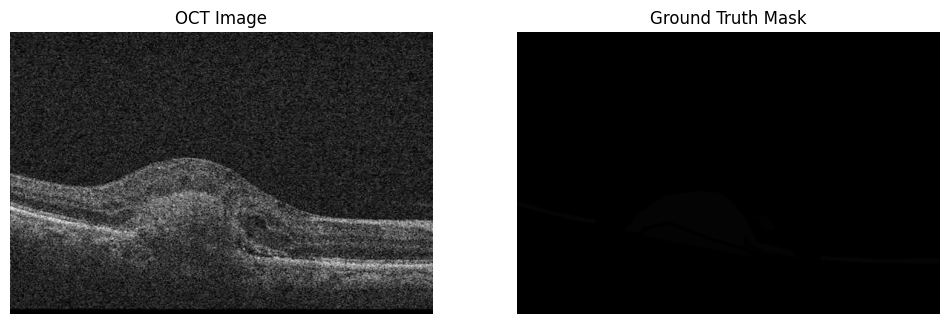

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_img)
plt.title("OCT Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample_mask)
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [ ]:
from collections import Counter

pixels = sample_mask.reshape(-1, 3)

color_counts = Counter(
    map(tuple, pixels)
)

print("Most common colors:\n")

for color, count in color_counts.most_common(15):

    print(
        color,
        "=>",
        count,
        "pixels"
    )

Most common colors:

(np.uint8(0), np.uint8(0), np.uint8(0)) => 204783 pixels
(np.uint8(4), np.uint8(4), np.uint8(4)) => 7613 pixels
(np.uint8(3), np.uint8(3), np.uint8(3)) => 1966 pixels
(np.uint8(5), np.uint8(5), np.uint8(5)) => 1560 pixels
(np.uint8(2), np.uint8(2), np.uint8(2)) => 342 pixels
(np.uint8(1), np.uint8(1), np.uint8(1)) => 336 pixels


In [ ]:
# Correct AMD-SD color mapping

COLOR_TO_CLASS = {

    (0, 0, 0): 0,        # Background

    (0, 0, 255): 1,     # SRF - Blue

    (255, 0, 0): 2,     # PED - Red

    (0, 255, 0): 3,     # IRF - Green

    (255, 255, 0): 4,   # SHRM - Yellow

    (0, 255, 255): 5    # IS/OS - Cyan
}

CLASS_NAMES = [
    "Background",
    "SRF",
    "PED",
    "IRF",
    "SHRM",
    "IS/OS"
]

NUM_CLASSES = 6

print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASS_NAMES)

Number of classes: 6
Classes: ['Background', 'SRF', 'PED', 'IRF', 'SHRM', 'IS/OS']


In [ ]:
def rgb_to_class_mask(mask_rgb):

    h, w, _ = mask_rgb.shape

    class_mask = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    for color, class_id in COLOR_TO_CLASS.items():

        match = np.all(
            mask_rgb == color,
            axis=-1
        )

        class_mask[match] = class_id

    return class_mask

In [ ]:
test_mask = np.array(
    Image.open(mask_files[0]).convert("RGB")
)

converted = rgb_to_class_mask(test_mask)

print(
    "Classes found:",
    np.unique(converted)
)

Classes found: [0]


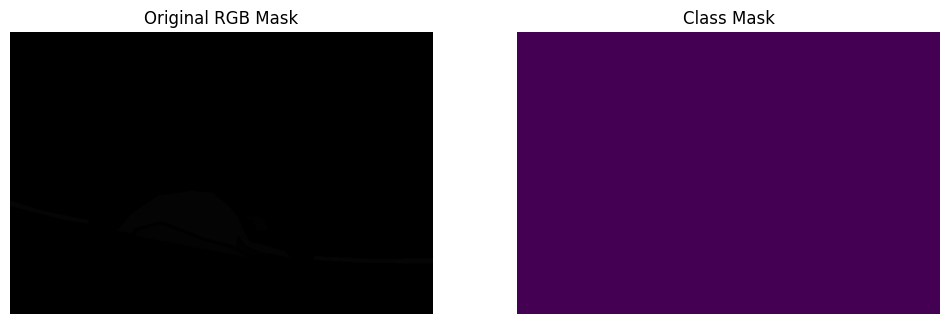

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_mask)
plt.title("Original RGB Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(converted_mask)
plt.title("Class Mask")
plt.axis("off")

plt.show()

In [ ]:
data = pd.DataFrame(
    pairs,
    columns=["image_path", "mask_path"]
)

data["filename"] = data["image_path"].apply(
    lambda x: os.path.basename(x)
)

data["eye_id"] = data["filename"].apply(
    lambda x: x.split("_")[0]
)

print(data.head())
print("\nTotal pairs:", len(data))
print("Unique eye IDs:", data["eye_id"].nunique())

                               image_path  \
0   /content/amd_dataset/images/75_16.png   
1   /content/amd_dataset/images/50_20.png   
2  /content/amd_dataset/images/144_14.png   
3  /content/amd_dataset/images/143_15.png   
4   /content/amd_dataset/images/130_4.png   

                               mask_path    filename eye_id  
0   /content/amd_dataset/masks/75_16.png   75_16.png     75  
1   /content/amd_dataset/masks/50_20.png   50_20.png     50  
2  /content/amd_dataset/masks/144_14.png  144_14.png    144  
3  /content/amd_dataset/masks/143_15.png  143_15.png    143  
4   /content/amd_dataset/masks/130_4.png   130_4.png    130  

Total pairs: 3049
Unique eye IDs: 156


In [ ]:
from sklearn.model_selection import train_test_split

unique_eyes = data["eye_id"].unique()

train_eyes, temp_eyes = train_test_split(
    unique_eyes,
    test_size=0.30,
    random_state=42
)

val_eyes, test_eyes = train_test_split(
    temp_eyes,
    test_size=0.50,
    random_state=42
)

print("Training eyes:", len(train_eyes))
print("Validation eyes:", len(val_eyes))
print("Test eyes:", len(test_eyes))

Training eyes: 109
Validation eyes: 23
Test eyes: 24


In [ ]:
train_df = data[
    data["eye_id"].isin(train_eyes)
].reset_index(drop=True)

val_df = data[
    data["eye_id"].isin(val_eyes)
].reset_index(drop=True)

test_df = data[
    data["eye_id"].isin(test_eyes)
].reset_index(drop=True)

In [ ]:
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Training images: 2100
Validation images: 491
Test images: 458


In [ ]:
print(
    "Train ∩ Validation:",
    len(set(train_eyes) & set(val_eyes))
)

print(
    "Train ∩ Test:",
    len(set(train_eyes) & set(test_eyes))
)

print(
    "Validation ∩ Test:",
    len(set(val_eyes) & set(test_eyes))
)

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

IMAGE_SIZE = 256

In [ ]:
train_transform = A.Compose([

    A.Resize(
        IMAGE_SIZE,
        IMAGE_SIZE
    ),

    A.HorizontalFlip(
        p=0.5
    ),

    A.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.10,
        rotate_limit=10,
        border_mode=0,
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.1,
        contrast_limit=0.1,
        p=0.3
    ),

    A.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    ),

    ToTensorV2()
])

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
val_transform = A.Compose([

    A.Resize(
        IMAGE_SIZE,
        IMAGE_SIZE
    ),

    A.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    ),

    ToTensorV2()
])

In [ ]:
import torch
from torch.utils.data import Dataset

class AMDSegmentationDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.transform = transform

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image_path = row["image_path"]
        mask_path = row["mask_path"]

        image = np.array(
            Image.open(image_path).convert("RGB")
        )

        mask_rgb = np.array(
            Image.open(mask_path).convert("RGB")
        )

        mask = rgb_to_class_mask(
            mask_rgb
        )

        if self.transform:

            transformed = self.transform(
                image=image,
                mask=mask
            )

            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask.long()

In [ ]:
train_dataset = AMDSegmentationDataset(
    train_df,
    transform=train_transform
)

val_dataset = AMDSegmentationDataset(
    val_df,
    transform=val_transform
)

test_dataset = AMDSegmentationDataset(
    test_df,
    transform=val_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 2100
Validation: 491
Test: 458


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
images, masks = next(
    iter(train_loader)
)

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Mask classes:", torch.unique(masks))

Images: torch.Size([8, 3, 256, 256])
Masks: torch.Size([8, 256, 256])
Mask classes: tensor([0])


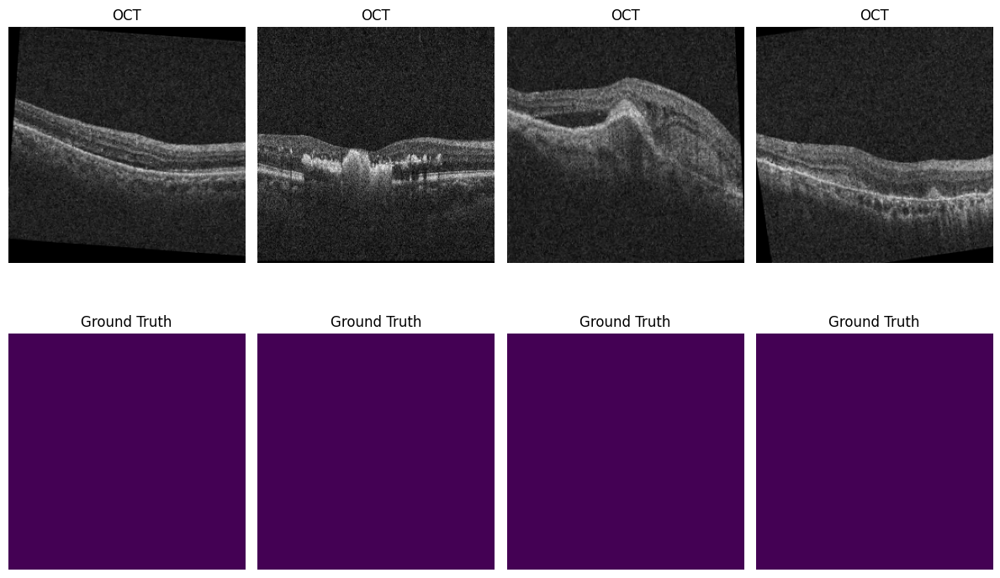

In [ ]:
plt.figure(figsize=(12, 8))

for i in range(4):

    img = images[i].permute(
        1, 2, 0
    ).numpy()

    img = img * 0.5 + 0.5
    img = np.clip(img, 0, 1)

    plt.subplot(2, 4, i + 1)

    plt.imshow(img)
    plt.title("OCT")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)

    plt.imshow(
        masks[i].numpy(),
        vmin=0,
        vmax=5
    )

    plt.title("Ground Truth")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cuda
GPU: Tesla T4


In [ ]:
!pip install -q segmentation-models-pytorch

In [ ]:
import segmentation_models_pytorch as smp
import torch.nn as nn

In [ ]:
unetpp = smp.UnetPlusPlus(

    encoder_name="resnet34",

    encoder_weights="imagenet",

    in_channels=3,

    classes=NUM_CLASSES
)

unetpp = unetpp.to(device)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        return self.block(x)

In [ ]:
class DeepUNet(nn.Module):

    def __init__(self, num_classes=6):

        super().__init__()

        self.pool = nn.MaxPool2d(2)

        # Encoder

        self.enc1 = DoubleConv(
            3, 64
        )

        self.enc2 = DoubleConv(
            64, 128
        )

        self.enc3 = DoubleConv(
            128, 256
        )

        self.enc4 = DoubleConv(
            256, 512
        )

        self.enc5 = DoubleConv(
            512, 1024
        )

        # Bottleneck

        self.bottleneck = DoubleConv(
            1024, 2048
        )

        # Decoder

        self.up5 = nn.ConvTranspose2d(
            2048,
            1024,
            kernel_size=2,
            stride=2
        )

        self.dec5 = DoubleConv(
            2048,
            1024
        )

        self.up4 = nn.ConvTranspose2d(
            1024,
            512,
            kernel_size=2,
            stride=2
        )

        self.dec4 = DoubleConv(
            1024,
            512
        )

        self.up3 = nn.ConvTranspose2d(
            512,
            256,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            512,
            256
        )

        self.up2 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            256,
            128
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            128,
            64
        )

        self.final = nn.Conv2d(
            64,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        e5 = self.enc5(
            self.pool(e4)
        )

        b = self.bottleneck(
            self.pool(e5)
        )

        # Decoder

        d5 = self.up5(b)

        d5 = torch.cat(
            [d5, e5],
            dim=1
        )

        d5 = self.dec5(d5)

        d4 = self.up4(d5)

        d4 = torch.cat(
            [d4, e4],
            dim=1
        )

        d4 = self.dec4(d4)

        d3 = self.up3(d4)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        return self.final(d1)

In [ ]:
deep_unet = DeepUNet(
    num_classes=NUM_CLASSES
).to(device)

In [ ]:
def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print(
    "U-Net++ parameters:",
    f"{count_parameters(unetpp):,}"
)

print(
    "Deep U-Net parameters:",
    f"{count_parameters(deep_unet):,}"
)

U-Net++ parameters: 26,079,334
Deep U-Net parameters: 124,386,566


In [ ]:
class CombinedLoss(nn.Module):

    def __init__(self):

        super().__init__()

        self.ce = nn.CrossEntropyLoss()

        self.dice = smp.losses.DiceLoss(
            mode="multiclass",
            from_logits=True
        )

    def forward(
        self,
        prediction,
        target
    ):

        ce_loss = self.ce(
            prediction,
            target
        )

        dice_loss = self.dice(
            prediction,
            target
        )

        return (
            0.5 * ce_loss
            +
            0.5 * dice_loss
        )

In [ ]:
criterion = CombinedLoss()

In [ ]:
def calculate_metrics(
    prediction,
    target,
    num_classes=6
):

    prediction = torch.argmax(
        prediction,
        dim=1
    )

    prediction = prediction.detach().cpu().numpy()
    target = target.detach().cpu().numpy()

    dice_scores = []
    iou_scores = []
    precision_scores = []
    recall_scores = []
    specificity_scores = []

    for cls in range(
        1,
        num_classes
    ):

        pred_cls = prediction == cls
        true_cls = target == cls

        TP = np.logical_and(
            pred_cls,
            true_cls
        ).sum()

        FP = np.logical_and(
            pred_cls,
            ~true_cls
        ).sum()

        FN = np.logical_and(
            ~pred_cls,
            true_cls
        ).sum()

        TN = np.logical_and(
            ~pred_cls,
            ~true_cls
        ).sum()

        dice = (
            2 * TP
            /
            (
                2 * TP
                + FP
                + FN
                + 1e-7
            )
        )

        iou = (
            TP
            /
            (
                TP
                + FP
                + FN
                + 1e-7
            )
        )

        precision = (
            TP
            /
            (
                TP
                + FP
                + 1e-7
            )
        )

        recall = (
            TP
            /
            (
                TP
                + FN
                + 1e-7
            )
        )

        specificity = (
            TN
            /
            (
                TN
                + FP
                + 1e-7
            )
        )

        dice_scores.append(dice)
        iou_scores.append(iou)
        precision_scores.append(precision)
        recall_scores.append(recall)
        specificity_scores.append(specificity)

    accuracy = (
        prediction == target
    ).mean()

    return {

        "accuracy": accuracy,

        "dice": np.mean(
            dice_scores
        ),

        "iou": np.mean(
            iou_scores
        ),

        "precision": np.mean(
            precision_scores
        ),

        "recall": np.mean(
            recall_scores
        ),

        "specificity": np.mean(
            specificity_scores
        )
    }

In [ ]:
def calculate_per_class_metrics(
    prediction,
    target,
    num_classes=6
):

    prediction = torch.argmax(
        prediction,
        dim=1
    )

    prediction = prediction.detach().cpu().numpy()
    target = target.detach().cpu().numpy()

    results = {}

    for cls in range(
        1,
        num_classes
    ):

        pred_cls = prediction == cls
        true_cls = target == cls

        TP = np.logical_and(
            pred_cls,
            true_cls
        ).sum()

        FP = np.logical_and(
            pred_cls,
            ~true_cls
        ).sum()

        FN = np.logical_and(
            ~pred_cls,
            true_cls
        ).sum()

        dice = (
            2 * TP
            /
            (
                2 * TP
                + FP
                + FN
                + 1e-7
            )
        )

        iou = (
            TP
            /
            (
                TP
                + FP
                + FN
                + 1e-7
            )
        )

        precision = (
            TP
            /
            (
                TP
                + FP
                + 1e-7
            )
        )

        recall = (
            TP
            /
            (
                TP
                + FN
                + 1e-7
            )
        )

        results[
            CLASS_NAMES[cls]
        ] = {

            "Dice": dice,

            "IoU": iou,

            "Precision": precision,

            "Recall": recall
        }

    return results

In [ ]:
import time

def train_model(
    model,
    model_name,
    train_loader,
    val_loader,
    epochs=30,
    patience=7
):

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3
    )

    history = []

    best_dice = -1

    epochs_without_improvement = 0

    start_time = time.time()

    for epoch in range(epochs):

        # -------------------------
        # TRAIN
        # -------------------------

        model.train()

        train_loss = 0

        for images, masks in train_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                masks
            )

            loss.backward()

            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(
            train_loader
        )

        # -------------------------
        # VALIDATION
        # -------------------------

        model.eval()

        val_loss = 0

        all_metrics = []

        with torch.no_grad():

            for images, masks in val_loader:

                images = images.to(
                    device,
                    non_blocking=True
                )

                masks = masks.to(
                    device,
                    non_blocking=True
                )

                outputs = model(images)

                loss = criterion(
                    outputs,
                    masks
                )

                val_loss += loss.item()

                metrics = calculate_metrics(
                    outputs,
                    masks
                )

                all_metrics.append(
                    metrics
                )

        val_loss /= len(
            val_loader
        )

        avg_metrics = {

            key: np.mean([
                m[key]
                for m in all_metrics
            ])

            for key in all_metrics[0]
        }

        scheduler.step(
            avg_metrics["dice"]
        )

        history.append({

            "epoch": epoch + 1,

            "train_loss": train_loss,

            "val_loss": val_loss,

            **avg_metrics
        })

        print(
            f"{model_name} | "
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Dice: {avg_metrics['dice']:.4f} | "
            f"IoU: {avg_metrics['iou']:.4f}"
        )

        # -------------------------
        # SAVE BEST MODEL
        # -------------------------

        if (
            avg_metrics["dice"]
            >
            best_dice
        ):

            best_dice = (
                avg_metrics["dice"]
            )

            epochs_without_improvement = 0

            torch.save(
                model.state_dict(),
                f"/content/best_{model_name}.pth"
            )

            print(
                "  ✓ Best model saved"
            )

        else:

            epochs_without_improvement += 1

        # -------------------------
        # EARLY STOPPING
        # -------------------------

        if (
            epochs_without_improvement
            >= patience
        ):

            print(
                f"\nEarly stopping at "
                f"epoch {epoch+1}"
            )

            break

    training_time = (
        time.time()
        -
        start_time
    )

    return (
        pd.DataFrame(history),
        training_time
    )

In [ ]:
unetpp_history, unetpp_time = train_model(
    unetpp,
    "unetpp",
    train_loader,
    val_loader,
    epochs=5,
    patience=3
)

KeyboardInterrupt: 

In [ ]:
deep_unet_history, deep_unet_time = train_model(
    deep_unet,
    "deep_unet",
    train_loader,
    val_loader,
    epochs=5,
    patience=3
)

In [ ]:
from PIL import Image
import numpy as np
from collections import Counter

# Take one actual mask
test_mask_path = mask_files[0]

img = Image.open(test_mask_path)

print("Mask path:", test_mask_path)
print("Image mode:", img.mode)
print("Image size:", img.size)

# Convert to RGB
mask_rgb = np.array(img.convert("RGB"))

print("Array shape:", mask_rgb.shape)

# Get all RGB colors and their pixel counts
pixels = mask_rgb.reshape(-1, 3)
color_counts = Counter(map(tuple, pixels))

print("\nUnique colors:", len(color_counts))
print("\nTop colors:")

for color, count in color_counts.most_common(20):
    print(color, "->", count)

Mask path: /content/amd_dataset/masks/75_16.png
Image mode: L
Image size: (570, 380)
Array shape: (380, 570, 3)

Unique colors: 6

Top colors:
(np.uint8(0), np.uint8(0), np.uint8(0)) -> 204783
(np.uint8(4), np.uint8(4), np.uint8(4)) -> 7613
(np.uint8(3), np.uint8(3), np.uint8(3)) -> 1966
(np.uint8(5), np.uint8(5), np.uint8(5)) -> 1560
(np.uint8(2), np.uint8(2), np.uint8(2)) -> 342
(np.uint8(1), np.uint8(1), np.uint8(1)) -> 336


In [ ]:
# Print only the RGB colors that actually exist
unique_colors = np.unique(mask_rgb.reshape(-1, 3), axis=0)

print("ALL UNIQUE RGB COLORS:")
for color in unique_colors:
    print(tuple(color))

ALL UNIQUE RGB COLORS:
(np.uint8(0), np.uint8(0), np.uint8(0))
(np.uint8(1), np.uint8(1), np.uint8(1))
(np.uint8(2), np.uint8(2), np.uint8(2))
(np.uint8(3), np.uint8(3), np.uint8(3))
(np.uint8(4), np.uint8(4), np.uint8(4))
(np.uint8(5), np.uint8(5), np.uint8(5))


In [ ]:
from PIL import Image
import numpy as np

test_mask_path = mask_files[0]

mask = np.array(Image.open(test_mask_path))

print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)
print("Unique classes:", np.unique(mask))

Mask shape: (380, 570)
Mask dtype: uint8
Unique classes: [0 1 2 3 4 5]


In [ ]:
from collections import Counter

mask = np.array(Image.open(mask_files[0]))

counts = Counter(mask.flatten())

print("Class pixel counts:")

for class_id in sorted(counts):
    print(f"Class {class_id}: {counts[class_id]} pixels")

Class pixel counts:
Class 0: 204783 pixels
Class 1: 336 pixels
Class 2: 342 pixels
Class 3: 1966 pixels
Class 4: 7613 pixels
Class 5: 1560 pixels


In [ ]:
mask = np.array(
    Image.open(mask_files[0]),
    dtype=np.uint8
)

print("Successfully loaded mask with shape:", mask.shape)

Successfully loaded mask with shape: (380, 570)


In [ ]:
class AMDSegmentationDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        # Read OCT image
        image = np.array(
            Image.open(row["image_path"]).convert("RGB")
        )

        # Read mask directly
        mask = np.array(
            Image.open(row["mask_path"]),
            dtype=np.uint8
        )

        # Make sure classes are 0-5
        assert set(np.unique(mask)).issubset(
            {0, 1, 2, 3, 4, 5}
        ), f"Unexpected mask classes: {np.unique(mask)}"

        if self.transform:

            transformed = self.transform(
                image=image,
                mask=mask
            )

            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask.long()

Image shape: (380, 570, 3)
Mask shape: (380, 570)
Mask classes: [0 1 2 3 4 5]


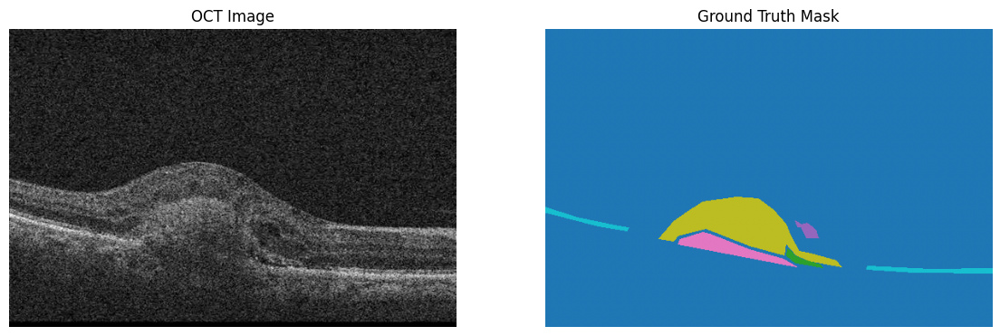

In [ ]:
import matplotlib.pyplot as plt

img_path = pairs[0][0]
mask_path = pairs[0][1]

image = np.array(
    Image.open(img_path).convert("RGB")
)

mask = np.array(
    Image.open(mask_path)
)

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask classes:", np.unique(mask))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("OCT Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="tab10", vmin=0, vmax=5)
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [ ]:
import pandas as pd
import os

data = pd.DataFrame(
    pairs,
    columns=["image_path", "mask_path"]
)

data["filename"] = data["image_path"].apply(
    lambda x: os.path.basename(x)
)

# Eye ID = part before first "_"
data["eye_id"] = data["filename"].apply(
    lambda x: x.split("_")[0]
)

print("Total matched pairs:", len(data))
print("Unique eyes:", data["eye_id"].nunique())

print("\nFirst 5 rows:")
display(data.head())

Total matched pairs: 3049
Unique eyes: 156

First 5 rows:


,image_path,mask_path,filename,eye_id
0,/content/amd_dataset/images/75_16.png,/content/amd_dataset/masks/75_16.png,75_16.png,75
1,/content/amd_dataset/images/50_20.png,/content/amd_dataset/masks/50_20.png,50_20.png,50
2,/content/amd_dataset/images/144_14.png,/content/amd_dataset/masks/144_14.png,144_14.png,144
3,/content/amd_dataset/images/143_15.png,/content/amd_dataset/masks/143_15.png,143_15.png,143
4,/content/amd_dataset/images/130_4.png,/content/amd_dataset/masks/130_4.png,130_4.png,130


In [ ]:
from sklearn.model_selection import train_test_split

unique_eyes = data["eye_id"].unique()

# 70% train, 30% temporary
train_eyes, temp_eyes = train_test_split(
    unique_eyes,
    test_size=0.30,
    random_state=42
)

# 15% validation, 15% test
val_eyes, test_eyes = train_test_split(
    temp_eyes,
    test_size=0.50,
    random_state=42
)

train_df = data[
    data["eye_id"].isin(train_eyes)
].reset_index(drop=True)

val_df = data[
    data["eye_id"].isin(val_eyes)
].reset_index(drop=True)

test_df = data[
    data["eye_id"].isin(test_eyes)
].reset_index(drop=True)

print("TRAIN")
print("Images:", len(train_df))
print("Eyes:", train_df["eye_id"].nunique())

print("\nVALIDATION")
print("Images:", len(val_df))
print("Eyes:", val_df["eye_id"].nunique())

print("\nTEST")
print("Images:", len(test_df))
print("Eyes:", test_df["eye_id"].nunique())

TRAIN
Images: 2100
Eyes: 109

VALIDATION
Images: 491
Eyes: 23

TEST
Images: 458
Eyes: 24


In [ ]:
!pip install -q segmentation-models-pytorch albumentations

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import segmentation_models_pytorch as smp
import albumentations as A

from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import time
import matplotlib.pyplot as plt

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB


In [ ]:
CLASS_NAMES = [
    "Background",
    "SRF",
    "PED",
    "IRF",
    "SHRM",
    "IS/OS"
]

NUM_CLASSES = 6

print(CLASS_NAMES)

['Background', 'SRF', 'PED', 'IRF', 'SHRM', 'IS/OS']


In [ ]:
IMAGE_SIZE = 256

train_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),

    A.HorizontalFlip(p=0.5),

    A.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.10,
        rotate_limit=10,
        border_mode=0,
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.10,
        contrast_limit=0.10,
        p=0.3
    ),

    A.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    ),

    ToTensorV2()
])


val_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),

    A.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    ),

    ToTensorV2()
])

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
class AMDSegmentationDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        # OCT image
        image = np.array(
            Image.open(row["image_path"]).convert("RGB")
        )

        # Mask is already 0-5
        mask = np.array(
            Image.open(row["mask_path"]),
            dtype=np.uint8
        )

        # Safety check
        assert set(np.unique(mask)).issubset(
            {0, 1, 2, 3, 4, 5}
        ), f"Unexpected classes: {np.unique(mask)}"

        if self.transform:

            transformed = self.transform(
                image=image,
                mask=mask
            )

            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask.long()

In [ ]:
train_dataset = AMDSegmentationDataset(
    train_df,
    transform=train_transform
)

val_dataset = AMDSegmentationDataset(
    val_df,
    transform=val_transform
)

test_dataset = AMDSegmentationDataset(
    test_df,
    transform=val_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 2100
Validation dataset: 491
Test dataset: 458


In [ ]:
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 525
Validation batches: 123
Test batches: 115


In [ ]:
images, masks = next(iter(train_loader))

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print("Mask classes:", torch.unique(masks))

Images shape: torch.Size([4, 3, 256, 256])
Masks shape: torch.Size([4, 256, 256])
Image dtype: torch.float32
Mask dtype: torch.int64
Mask classes: tensor([0, 1, 2, 3, 4, 5])


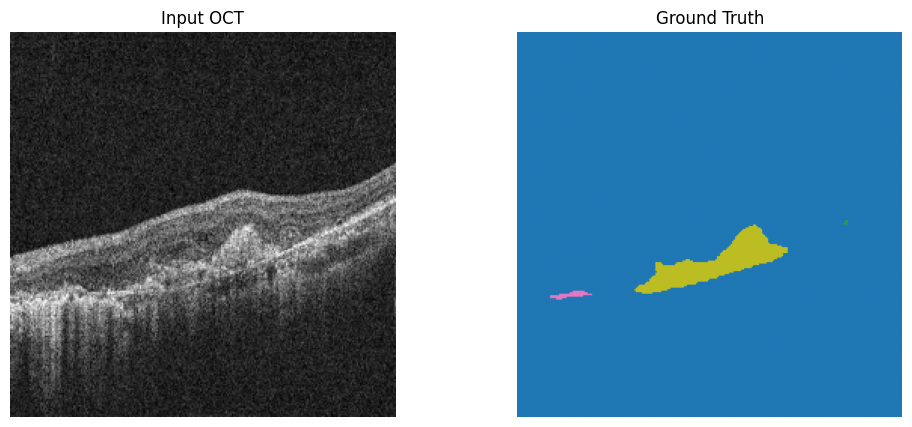

In [ ]:
image = images[0].permute(1, 2, 0).numpy()
mask = masks[0].numpy()

# Undo normalization
image = image * 0.5 + 0.5
image = np.clip(image, 0, 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Input OCT")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="tab10", vmin=0, vmax=5)
plt.title("Ground Truth")
plt.axis("off")

plt.show()

In [ ]:
unetpp = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
)

unetpp = unetpp.to(device)

print("U-Net++ created successfully.")

U-Net++ created successfully.


In [ ]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class DeepUNet(nn.Module):

    def __init__(self, num_classes=6):

        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)
        self.enc5 = ConvBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Decoder
        self.up4 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )

        self.dec4 = ConvBlock(512, 256)

        self.up3 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )

        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )

        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(
            64, 32, kernel_size=2, stride=2
        )

        self.dec1 = ConvBlock(64, 32)

        self.final = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        e5 = self.enc5(
            self.pool(e4)
        )

        # Decoder
        d4 = self.up4(e5)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)

In [ ]:
deep_unet = DeepUNet(
    num_classes=NUM_CLASSES
).to(device)

print("Deep U-Net created successfully.")

Deep U-Net created successfully.


In [ ]:
def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


unetpp_params = count_parameters(unetpp)
deep_unet_params = count_parameters(deep_unet)

print(
    "U-Net++ parameters:",
    f"{unetpp_params:,}"
)

print(
    "Deep U-Net parameters:",
    f"{deep_unet_params:,}"
)

U-Net++ parameters: 26,079,334
Deep U-Net parameters: 7,766,150


In [ ]:
dice_loss = smp.losses.DiceLoss(
    mode="multiclass",
    from_logits=True
)

ce_loss = nn.CrossEntropyLoss()


def combined_loss(pred, target):

    loss_ce = ce_loss(pred, target)

    loss_dice = dice_loss(pred, target)

    return 0.5 * loss_ce + 0.5 * loss_dice

In [ ]:
def calculate_metrics(model, loader):

    model.eval()

    total_correct = 0
    total_pixels = 0

    tp = np.zeros(NUM_CLASSES, dtype=np.float64)
    fp = np.zeros(NUM_CLASSES, dtype=np.float64)
    fn = np.zeros(NUM_CLASSES, dtype=np.float64)
    tn = np.zeros(NUM_CLASSES, dtype=np.float64)

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = model(images)

            preds = torch.argmax(
                outputs,
                dim=1
            )

            total_correct += (
                preds == masks
            ).sum().item()

            total_pixels += masks.numel()

            for c in range(NUM_CLASSES):

                pred_c = preds == c
                mask_c = masks == c

                tp[c] += (
                    pred_c & mask_c
                ).sum().item()

                fp[c] += (
                    pred_c & ~mask_c
                ).sum().item()

                fn[c] += (
                    ~pred_c & mask_c
                ).sum().item()

                tn[c] += (
                    ~pred_c & ~mask_c
                ).sum().item()

    accuracy = total_correct / total_pixels

    dice = (
        2 * tp /
        (2 * tp + fp + fn + 1e-8)
    )

    iou = (
        tp /
        (tp + fp + fn + 1e-8)
    )

    precision = (
        tp /
        (tp + fp + 1e-8)
    )

    recall = (
        tp /
        (tp + fn + 1e-8)
    )

    specificity = (
        tn /
        (tn + fp + 1e-8)
    )

    # Exclude background from mean lesion metrics
    mean_dice = np.mean(dice[1:])
    mean_iou = np.mean(iou[1:])
    mean_precision = np.mean(precision[1:])
    mean_recall = np.mean(recall[1:])
    mean_specificity = np.mean(specificity[1:])

    return {
        "accuracy": accuracy,
        "mean_dice": mean_dice,
        "mean_iou": mean_iou,
        "mean_precision": mean_precision,
        "mean_recall": mean_recall,
        "mean_specificity": mean_specificity,
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "specificity": specificity
    }

In [ ]:
def train_model(
    model,
    train_loader,
    val_loader,
    model_name,
    epochs=5
):

    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )

    best_dice = -1

    history = {
        "train_loss": [],
        "val_dice": [],
        "val_iou": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0

        for images, masks in train_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = combined_loss(
                    outputs,
                    masks
                )

            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

            running_loss += loss.item()

        avg_train_loss = (
            running_loss /
            len(train_loader)
        )

        # Validation
        metrics = calculate_metrics(
            model,
            val_loader
        )

        val_dice = metrics["mean_dice"]
        val_iou = metrics["mean_iou"]

        scheduler.step(val_dice)

        history["train_loss"].append(
            avg_train_loss
        )

        history["val_dice"].append(
            val_dice
        )

        history["val_iou"].append(
            val_iou
        )

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {avg_train_loss:.4f} | "
            f"Dice: {val_dice:.4f} | "
            f"IoU: {val_iou:.4f}"
        )

        # Save best model
        if val_dice > best_dice:

            best_dice = val_dice

            torch.save(
                model.state_dict(),
                f"/content/best_{model_name}.pth"
            )

            print(
                f"  ✓ Best {model_name} model saved"
            )

    training_time = time.time() - start_time

    print(
        f"\n{model_name} training time: "
        f"{training_time/60:.2f} minutes"
    )

    # Load best model
    model.load_state_dict(
        torch.load(
            f"/content/best_{model_name}.pth",
            map_location=device
        )
    )

    return model, history, training_time

In [ ]:
unetpp, unetpp_history, unetpp_training_time = train_model(
    unetpp,
    train_loader,
    val_loader,
    model_name="unetpp",
    epochs=5
)

Epoch [1/5] Loss: 0.5203 | Dice: 0.5997 | IoU: 0.4822
  ✓ Best unetpp model saved
Epoch [2/5] Loss: 0.2097 | Dice: 0.6051 | IoU: 0.4950
  ✓ Best unetpp model saved
Epoch [3/5] Loss: 0.1515 | Dice: 0.7654 | IoU: 0.6299
  ✓ Best unetpp model saved
Epoch [4/5] Loss: 0.1263 | Dice: 0.7606 | IoU: 0.6227
Epoch [5/5] Loss: 0.1181 | Dice: 0.7792 | IoU: 0.6456
  ✓ Best unetpp model saved

unetpp training time: 5.57 minutes


In [ ]:
deep_unet, deep_unet_history, deep_unet_training_time = train_model(
    deep_unet,
    train_loader,
    val_loader,
    model_name="deep_unet",
    epochs=5
)

Epoch [1/5] Loss: 0.8477 | Dice: 0.2997 | IoU: 0.2052
  ✓ Best deep_unet model saved
Epoch [2/5] Loss: 0.5256 | Dice: 0.5903 | IoU: 0.4719
  ✓ Best deep_unet model saved
Epoch [3/5] Loss: 0.3495 | Dice: 0.7370 | IoU: 0.5917
  ✓ Best deep_unet model saved
Epoch [4/5] Loss: 0.2413 | Dice: 0.7429 | IoU: 0.5955
  ✓ Best deep_unet model saved
Epoch [5/5] Loss: 0.1877 | Dice: 0.7699 | IoU: 0.6309
  ✓ Best deep_unet model saved

deep_unet training time: 4.16 minutes


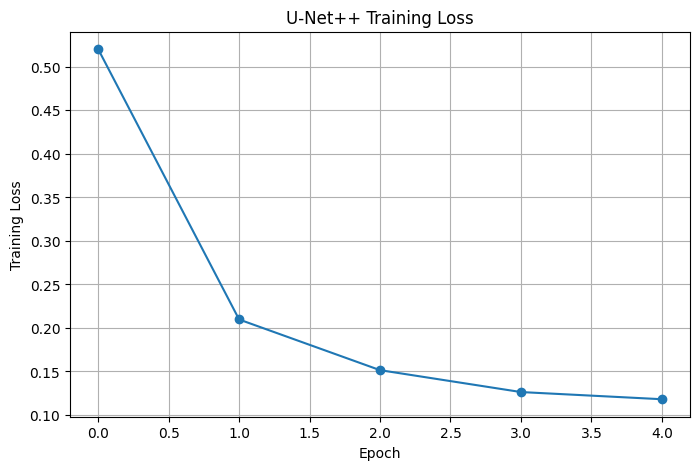

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    unetpp_history["train_loss"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("U-Net++ Training Loss")

plt.grid()
plt.show()

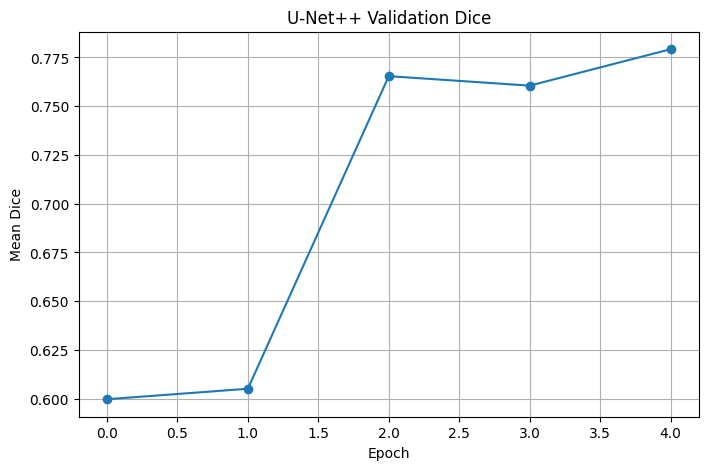

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    unetpp_history["val_dice"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Dice")
plt.title("U-Net++ Validation Dice")

plt.grid()
plt.show()

In [ ]:
unetpp_test_metrics = calculate_metrics(
    unetpp,
    test_loader
)

print("U-NET++ TEST RESULTS")
print("=" * 40)

print(
    "Accuracy:",
    f"{unetpp_test_metrics['accuracy']:.4f}"
)

print(
    "Mean Dice:",
    f"{unetpp_test_metrics['mean_dice']:.4f}"
)

print(
    "Mean IoU:",
    f"{unetpp_test_metrics['mean_iou']:.4f}"
)

print(
    "Precision:",
    f"{unetpp_test_metrics['mean_precision']:.4f}"
)

print(
    "Recall/Sensitivity:",
    f"{unetpp_test_metrics['mean_recall']:.4f}"
)

print(
    "Specificity:",
    f"{unetpp_test_metrics['mean_specificity']:.4f}"
)

U-NET++ TEST RESULTS
Accuracy: 0.9864
Mean Dice: 0.7480
Mean IoU: 0.6005
Precision: 0.7255
Recall/Sensitivity: 0.7753
Specificity: 0.9983


In [ ]:
print("\nPER-BIOMARKER RESULTS")
print("=" * 70)

for i in range(1, NUM_CLASSES):

    print(
        f"{CLASS_NAMES[i]:10s} | "
        f"Dice: {unetpp_test_metrics['dice'][i]:.4f} | "
        f"IoU: {unetpp_test_metrics['iou'][i]:.4f} | "
        f"Precision: {unetpp_test_metrics['precision'][i]:.4f} | "
        f"Recall: {unetpp_test_metrics['recall'][i]:.4f} | "
        f"Specificity: {unetpp_test_metrics['specificity'][i]:.4f}"
    )


PER-BIOMARKER RESULTS
SRF        | Dice: 0.7394 | IoU: 0.5865 | Precision: 0.6726 | Recall: 0.8209 | Specificity: 0.9986
PED        | Dice: 0.8068 | IoU: 0.6761 | Precision: 0.7519 | Recall: 0.8703 | Specificity: 0.9996
IRF        | Dice: 0.6721 | IoU: 0.5062 | Precision: 0.6760 | Recall: 0.6683 | Specificity: 0.9981
SHRM       | Dice: 0.7085 | IoU: 0.5486 | Precision: 0.7224 | Recall: 0.6952 | Specificity: 0.9966
IS/OS      | Dice: 0.8132 | IoU: 0.6852 | Precision: 0.8046 | Recall: 0.8220 | Specificity: 0.9989


In [ ]:
deep_unet_test_metrics = calculate_metrics(
    deep_unet,
    test_loader
)

print("DEEP U-NET TEST RESULTS")
print("=" * 40)

print(
    "Accuracy:",
    f"{deep_unet_test_metrics['accuracy']:.4f}"
)

print(
    "Mean Dice:",
    f"{deep_unet_test_metrics['mean_dice']:.4f}"
)

print(
    "Mean IoU:",
    f"{deep_unet_test_metrics['mean_iou']:.4f}"
)

print(
    "Precision:",
    f"{deep_unet_test_metrics['mean_precision']:.4f}"
)

print(
    "Recall/Sensitivity:",
    f"{deep_unet_test_metrics['mean_recall']:.4f}"
)

print(
    "Specificity:",
    f"{deep_unet_test_metrics['mean_specificity']:.4f}"
)

DEEP U-NET TEST RESULTS
Accuracy: 0.9854
Mean Dice: 0.7242
Mean IoU: 0.5692
Precision: 0.6768
Recall/Sensitivity: 0.7884
Specificity: 0.9980


In [ ]:
comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Mean Dice",
        "Mean IoU",
        "Precision",
        "Recall / Sensitivity",
        "Specificity",
        "Parameters",
        "Training Time (min)"
    ],

    "U-Net++": [
        unetpp_test_metrics["accuracy"],
        unetpp_test_metrics["mean_dice"],
        unetpp_test_metrics["mean_iou"],
        unetpp_test_metrics["mean_precision"],
        unetpp_test_metrics["mean_recall"],
        unetpp_test_metrics["mean_specificity"],
        unetpp_params,
        unetpp_training_time / 60
    ],

    "Deep U-Net": [
        deep_unet_test_metrics["accuracy"],
        deep_unet_test_metrics["mean_dice"],
        deep_unet_test_metrics["mean_iou"],
        deep_unet_test_metrics["mean_precision"],
        deep_unet_test_metrics["mean_recall"],
        deep_unet_test_metrics["mean_specificity"],
        deep_unet_params,
        deep_unet_training_time / 60
    ]
})

display(comparison)

,Metric,U-Net++,Deep U-Net
0,Accuracy,9.863660e-01,9.853839e-01
1,Mean Dice,7.479942e-01,7.242346e-01
2,Mean IoU,6.005186e-01,5.691947e-01
3,Precision,7.254859e-01,6.767990e-01
4,Recall / Sensitivity,7.753253e-01,7.883783e-01
5,Specificity,9.983440e-01,9.980305e-01
6,Parameters,2.607933e+07,7.766150e+06
7,Training Time (min),5.566591e+00,4.164299e+00


In [ ]:
def visualize_predictions(
    model1,
    model2,
    dataset,
    index=0
):

    image, mask = dataset[index]

    input_tensor = image.unsqueeze(0).to(device)

    model1.eval()
    model2.eval()

    with torch.no_grad():

        pred1 = torch.argmax(
            model1(input_tensor),
            dim=1
        )[0].cpu().numpy()

        pred2 = torch.argmax(
            model2(input_tensor),
            dim=1
        )[0].cpu().numpy()

    img = image.permute(1, 2, 0).numpy()

    img = img * 0.5 + 0.5
    img = np.clip(img, 0, 1)

    gt = mask.numpy()

    plt.figure(figsize=(16, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(img)
    plt.title("OCT Image")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(gt, cmap="tab10", vmin=0, vmax=5)
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(pred1, cmap="tab10", vmin=0, vmax=5)
    plt.title("U-Net++")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(pred2, cmap="tab10", vmin=0, vmax=5)
    plt.title("Deep U-Net")
    plt.axis("off")

    plt.show()

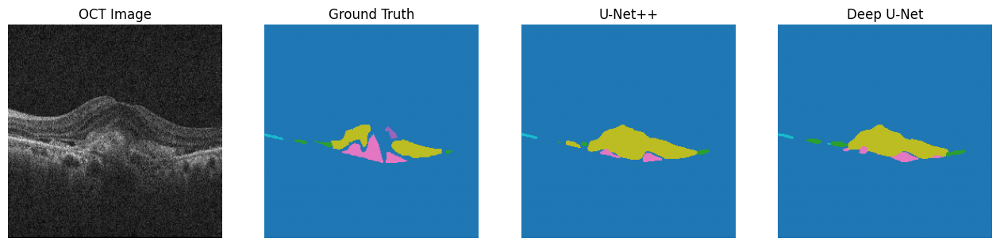

In [ ]:

visualize_predictions(
    unetpp,
    deep_unet,
    test_dataset,
    index=10
)

## AMD-SD Biomarker Class Mapping

| Class | Biomarker | Meaning | Official Display Color |
|:---:|---|---|:---:|
| 0 | **Background** | Normal/non-lesion area | Black |
| 1 | **SRF** | Subretinal Fluid | Red |
| 2 | **PED** | Pigment Epithelial Detachment |  Blue |
| 3 | **IRF** | Intraretinal Fluid |  Green |
| 4 | **SHRM** | Subretinal Hyperreflective Material | Yellow |
| 5 | **IS/OS** | Ellipsoid zone / photoreceptor junction disruption | Pink |

In [ ]:
from matplotlib.colors import ListedColormap

amd_colors = [
    "black",    # 0 Background
    "red",      # 1 SRF
    "blue",     # 2 PED
    "green",    # 3 IRF
    "yellow",   # 4 SHRM
    "pink"      # 5 IS/OS
]

amd_cmap = ListedColormap(amd_colors)

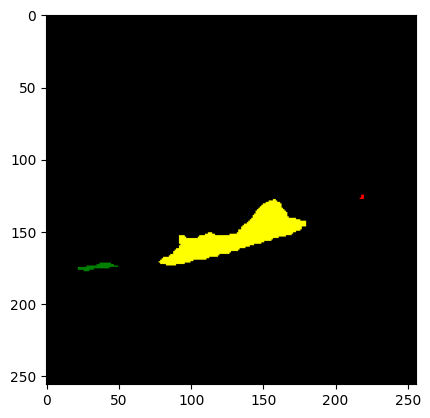

In [ ]:
plt.imshow(mask, cmap=amd_cmap, vmin=0, vmax=5)

In [ ]:
# Recreate U-Net++

unetpp = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
).to(device)

print("Fresh U-Net++ created")

Fresh U-Net++ created


In [ ]:
# Recreate Deep U-Net

deep_unet = DeepUNet(
    num_classes=NUM_CLASSES
).to(device)

print("Fresh Deep U-Net created")

Fresh Deep U-Net created


In [ ]:





unetpp, unetpp_history, unetpp_training_time = train_model(
    unetpp,
    train_loader,
    val_loader,
    model_name="unetpp",
    epochs=30
)

Epoch [1/30] Loss: 0.5833 | Dice: 0.6092 | IoU: 0.4949
  ✓ Best unetpp model saved
Epoch [2/30] Loss: 0.2180 | Dice: 0.6230 | IoU: 0.5124
  ✓ Best unetpp model saved
Epoch [3/30] Loss: 0.1542 | Dice: 0.7648 | IoU: 0.6262
  ✓ Best unetpp model saved
Epoch [4/30] Loss: 0.1284 | Dice: 0.7614 | IoU: 0.6241
Epoch [5/30] Loss: 0.1176 | Dice: 0.7922 | IoU: 0.6628
  ✓ Best unetpp model saved
Epoch [6/30] Loss: 0.1105 | Dice: 0.7978 | IoU: 0.6694
  ✓ Best unetpp model saved
Epoch [7/30] Loss: 0.1045 | Dice: 0.7671 | IoU: 0.6301
Epoch [8/30] Loss: 0.1030 | Dice: 0.8054 | IoU: 0.6798
  ✓ Best unetpp model saved
Epoch [9/30] Loss: 0.0984 | Dice: 0.7935 | IoU: 0.6630
Epoch [10/30] Loss: 0.0963 | Dice: 0.7972 | IoU: 0.6688
Epoch [11/30] Loss: 0.0953 | Dice: 0.8033 | IoU: 0.6768
Epoch [12/30] Loss: 0.0881 | Dice: 0.8082 | IoU: 0.6833
  ✓ Best unetpp model saved
Epoch [13/30] Loss: 0.0853 | Dice: 0.8000 | IoU: 0.6727
Epoch [14/30] Loss: 0.0848 | Dice: 0.7980 | IoU: 0.6706
Epoch [15/30] Loss: 0.0834 | 

In [ ]:
deep_unet, deep_unet_history, deep_unet_training_time = train_model(
    deep_unet,
    train_loader,
    val_loader,
    model_name="deep_unet",
    epochs=30
)

Epoch [1/30] Loss: 0.8289 | Dice: 0.3976 | IoU: 0.2893
  ✓ Best deep_unet model saved
Epoch [2/30] Loss: 0.4815 | Dice: 0.5920 | IoU: 0.4759
  ✓ Best deep_unet model saved
Epoch [3/30] Loss: 0.3268 | Dice: 0.5765 | IoU: 0.4579
Epoch [4/30] Loss: 0.2396 | Dice: 0.7611 | IoU: 0.6180
  ✓ Best deep_unet model saved
Epoch [5/30] Loss: 0.1842 | Dice: 0.7737 | IoU: 0.6365
  ✓ Best deep_unet model saved
Epoch [6/30] Loss: 0.1615 | Dice: 0.7655 | IoU: 0.6261
Epoch [7/30] Loss: 0.1461 | Dice: 0.7770 | IoU: 0.6400
  ✓ Best deep_unet model saved
Epoch [8/30] Loss: 0.1363 | Dice: 0.7696 | IoU: 0.6322
Epoch [9/30] Loss: 0.1285 | Dice: 0.7672 | IoU: 0.6291
Epoch [10/30] Loss: 0.1270 | Dice: 0.7749 | IoU: 0.6409
Epoch [11/30] Loss: 0.1138 | Dice: 0.7886 | IoU: 0.6575
  ✓ Best deep_unet model saved
Epoch [12/30] Loss: 0.1113 | Dice: 0.7919 | IoU: 0.6620
  ✓ Best deep_unet model saved
Epoch [13/30] Loss: 0.1096 | Dice: 0.7974 | IoU: 0.6688
  ✓ Best deep_unet model saved
Epoch [14/30] Loss: 0.1073 | Dice

In [ ]:
unetpp_test_metrics = calculate_metrics(
    unetpp,
    test_loader
)

print("========== U-NET++ TEST RESULTS ==========")

print("Accuracy:",
      f"{unetpp_test_metrics['accuracy']:.4f}")

print("Mean Dice:",
      f"{unetpp_test_metrics['mean_dice']:.4f}")

print("Mean IoU:",
      f"{unetpp_test_metrics['mean_iou']:.4f}")

print("Precision:",
      f"{unetpp_test_metrics['mean_precision']:.4f}")

print("Recall / Sensitivity:",
      f"{unetpp_test_metrics['mean_recall']:.4f}")

print("Specificity:",
      f"{unetpp_test_metrics['mean_specificity']:.4f}")

========== U-NET++ TEST RESULTS ==========
Accuracy: 0.9883
Mean Dice: 0.7827
Mean IoU: 0.6461
Precision: 0.7880
Recall / Sensitivity: 0.7839
Specificity: 0.9988


In [ ]:
deep_unet_test_metrics = calculate_metrics(
    deep_unet,
    test_loader
)

print("========== DEEP U-NET TEST RESULTS ==========")

print("Accuracy:",
      f"{deep_unet_test_metrics['accuracy']:.4f}")

print("Mean Dice:",
      f"{deep_unet_test_metrics['mean_dice']:.4f}")

print("Mean IoU:",
      f"{deep_unet_test_metrics['mean_iou']:.4f}")

print("Precision:",
      f"{deep_unet_test_metrics['mean_precision']:.4f}")

print("Recall / Sensitivity:",
      f"{deep_unet_test_metrics['mean_recall']:.4f}")

print("Specificity:",
      f"{deep_unet_test_metrics['mean_specificity']:.4f}")

========== DEEP U-NET TEST RESULTS ==========
Accuracy: 0.9871
Mean Dice: 0.7623
Mean IoU: 0.6207
Precision: 0.7454
Recall / Sensitivity: 0.7858
Specificity: 0.9984


In [ ]:
print("========== U-NET++ PER-BIOMARKER RESULTS ==========")

for i in range(1, NUM_CLASSES):

    print(
        f"{CLASS_NAMES[i]:10s} | "
        f"Dice: {unetpp_test_metrics['dice'][i]:.4f} | "
        f"IoU: {unetpp_test_metrics['iou'][i]:.4f} | "
        f"Precision: {unetpp_test_metrics['precision'][i]:.4f} | "
        f"Recall: {unetpp_test_metrics['recall'][i]:.4f} | "
        f"Specificity: {unetpp_test_metrics['specificity'][i]:.4f}"
    )

========== U-NET++ PER-BIOMARKER RESULTS ==========
SRF        | Dice: 0.7470 | IoU: 0.5962 | Precision: 0.6689 | Recall: 0.8457 | Specificity: 0.9985
PED        | Dice: 0.8645 | IoU: 0.7614 | Precision: 0.8746 | Recall: 0.8547 | Specificity: 0.9998
IRF        | Dice: 0.7392 | IoU: 0.5863 | Precision: 0.7921 | Recall: 0.6929 | Specificity: 0.9989
SHRM       | Dice: 0.7392 | IoU: 0.5863 | Precision: 0.7826 | Recall: 0.7003 | Specificity: 0.9975
IS/OS      | Dice: 0.8238 | IoU: 0.7004 | Precision: 0.8217 | Recall: 0.8259 | Specificity: 0.9990


In [ ]:
comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Mean Dice",
        "Mean IoU",
        "Precision",
        "Recall / Sensitivity",
        "Specificity",
        "Parameters",
        "Training Time (min)"
    ],

    "U-Net++": [
        unetpp_test_metrics["accuracy"],
        unetpp_test_metrics["mean_dice"],
        unetpp_test_metrics["mean_iou"],
        unetpp_test_metrics["mean_precision"],
        unetpp_test_metrics["mean_recall"],
        unetpp_test_metrics["mean_specificity"],
        count_parameters(unetpp),
        unetpp_training_time / 60
    ],

    "Deep U-Net": [
        deep_unet_test_metrics["accuracy"],
        deep_unet_test_metrics["mean_dice"],
        deep_unet_test_metrics["mean_iou"],
        deep_unet_test_metrics["mean_precision"],
        deep_unet_test_metrics["mean_recall"],
        deep_unet_test_metrics["mean_specificity"],
        count_parameters(deep_unet),
        deep_unet_training_time / 60
    ]
})

display(comparison)

,Metric,U-Net++,Deep U-Net
0,Accuracy,9.883013e-01,9.870659e-01
1,Mean Dice,7.827396e-01,7.623263e-01
2,Mean IoU,6.460980e-01,6.207008e-01
3,Precision,7.880087e-01,7.453943e-01
4,Recall / Sensitivity,7.838846e-01,7.858277e-01
5,Specificity,9.987537e-01,9.983877e-01
6,Parameters,2.607933e+07,7.766150e+06
7,Training Time (min),3.296379e+01,2.455910e+01


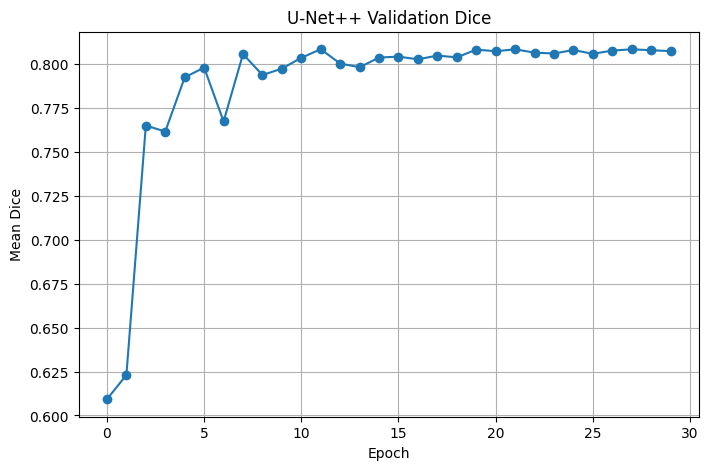

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    unetpp_history["val_dice"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Dice")
plt.title("U-Net++ Validation Dice")

plt.grid()
plt.show()

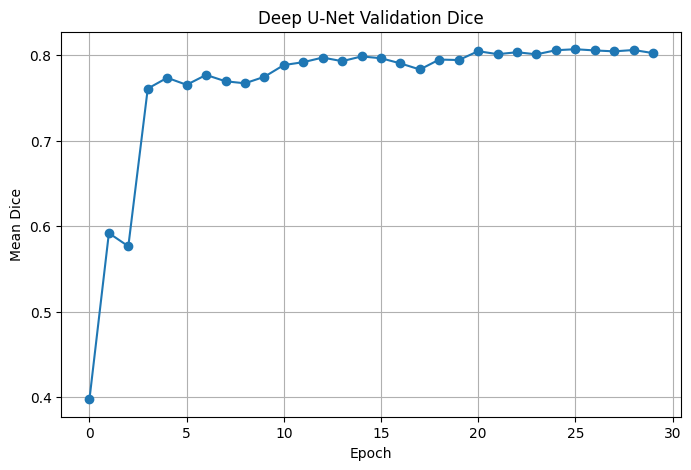

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    deep_unet_history["val_dice"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Dice")
plt.title("Deep U-Net Validation Dice")

plt.grid()
plt.show()

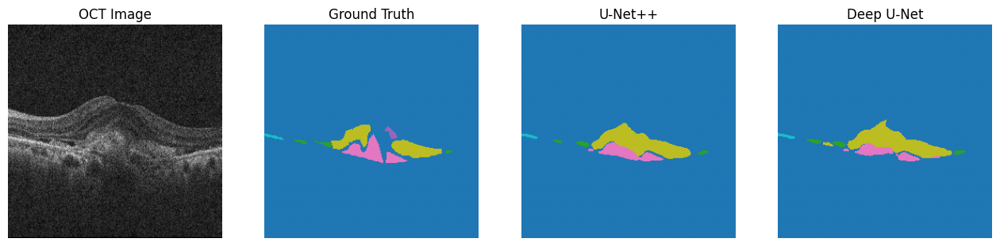

In [ ]:
visualize_predictions(
    unetpp,
    deep_unet,
    test_dataset,
    index=10
)

In [ ]:
best_unetpp_epoch = np.argmax(unetpp_history["val_dice"]) + 1
best_unetpp_dice = max(unetpp_history["val_dice"])

best_deep_epoch = np.argmax(deep_unet_history["val_dice"]) + 1
best_deep_dice = max(deep_unet_history["val_dice"])

print("U-Net++")
print("Best Epoch:", best_unetpp_epoch)
print("Best Validation Dice:", best_unetpp_dice)

print("\nDeep U-Net")
print("Best Epoch:", best_deep_epoch)
print("Best Validation Dice:", best_deep_dice)

U-Net++
Best Epoch: 12
Best Validation Dice: 0.8082021957380011

Deep U-Net
Best Epoch: 26
Best Validation Dice: 0.8071139425531388


In [ ]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import numpy as np
import torch

# AMD-SD official display colors
amd_colors = [
    "black",   # 0 Background
    "red",     # 1 SRF
    "blue",    # 2 PED
    "green",   # 3 IRF
    "yellow",  # 4 SHRM
    "pink"     # 5 IS/OS
]

amd_cmap = ListedColormap(amd_colors)


def visualize_predictions(
    model1,
    model2,
    dataset,
    index=10
):

    image, mask = dataset[index]

    input_tensor = image.unsqueeze(0).to(device)

    model1.eval()
    model2.eval()

    with torch.no_grad():

        pred1 = torch.argmax(
            model1(input_tensor),
            dim=1
        )[0].cpu().numpy()

        pred2 = torch.argmax(
            model2(input_tensor),
            dim=1
        )[0].cpu().numpy()

    # Convert image back from normalization
    img = image.permute(1, 2, 0).cpu().numpy()

    img = img * 0.5 + 0.5
    img = np.clip(img, 0, 1)

    gt = mask.cpu().numpy()

    # Plot
    fig, axes = plt.subplots(
        1, 4,
        figsize=(18, 5)
    )

    axes[0].imshow(img)
    axes[0].set_title("OCT Image", fontsize=13)
    axes[0].axis("off")

    axes[1].imshow(
        gt,
        cmap=amd_cmap,
        vmin=0,
        vmax=5
    )
    axes[1].set_title("Ground Truth", fontsize=13)
    axes[1].axis("off")

    axes[2].imshow(
        pred1,
        cmap=amd_cmap,
        vmin=0,
        vmax=5
    )
    axes[2].set_title("U-Net++", fontsize=13)
    axes[2].axis("off")

    axes[3].imshow(
        pred2,
        cmap=amd_cmap,
        vmin=0,
        vmax=5
    )
    axes[3].set_title("Deep U-Net", fontsize=13)
    axes[3].axis("off")

    # Legend
    legend_labels = [
        "Background",
        "SRF",
        "PED",
        "IRF",
        "SHRM",
        "IS/OS"
    ]

    from matplotlib.patches import Patch

    legend_colors = [
        "black",
        "red",
        "blue",
        "green",
        "yellow",
        "pink"
    ]

    handles = [
        Patch(
            facecolor=color,
            edgecolor="black",
            label=label
        )
        for color, label
        in zip(legend_colors, legend_labels)
    ]

    fig.legend(
        handles=handles,
        loc="lower center",
        ncol=6,
        bbox_to_anchor=(0.5, -0.02)
    )

    plt.tight_layout()
    plt.show()

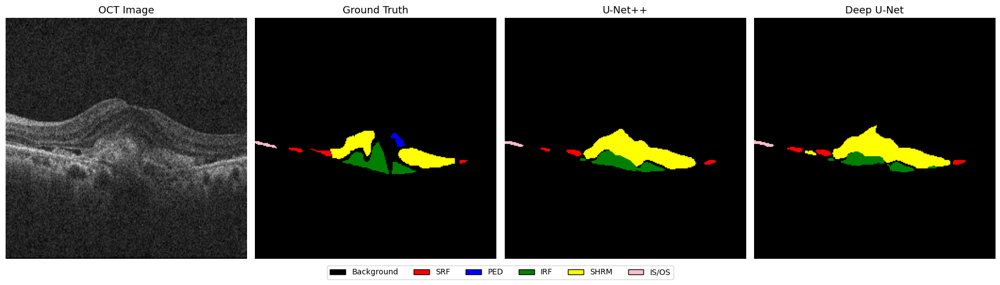

In [ ]:
visualize_predictions(
    unetpp,
    deep_unet,
    test_dataset,
    index=10
)

In [ ]:
unetpp_test_metrics = calculate_metrics(
    unetpp,
    test_loader
)

deep_unet_test_metrics = calculate_metrics(
    deep_unet,
    test_loader
)

In [ ]:
print("U-Net++")
print("Accuracy:", unetpp_test_metrics["accuracy"])
print("Mean Dice:", unetpp_test_metrics["mean_dice"])
print("Mean IoU:", unetpp_test_metrics["mean_iou"])
print("Precision:", unetpp_test_metrics["mean_precision"])
print("Recall:", unetpp_test_metrics["mean_recall"])
print("Specificity:", unetpp_test_metrics["mean_specificity"])

print("\nDeep U-Net")
print("Accuracy:", deep_unet_test_metrics["accuracy"])
print("Mean Dice:", deep_unet_test_metrics["mean_dice"])
print("Mean IoU:", deep_unet_test_metrics["mean_iou"])
print("Precision:", deep_unet_test_metrics["mean_precision"])
print("Recall:", deep_unet_test_metrics["mean_recall"])
print("Specificity:", deep_unet_test_metrics["mean_specificity"])

U-Net++
Accuracy: 0.9883013396283945
Mean Dice: 0.7827395789294539
Mean IoU: 0.64609798704984
Precision: 0.788008685490676
Recall: 0.7838845567595506
Specificity: 0.998753714733617

Deep U-Net
Accuracy: 0.9870658774563319
Mean Dice: 0.7623263307401247
Mean IoU: 0.6207008431892665
Precision: 0.745394299871311
Recall: 0.7858276888414661
Specificity: 0.9983876806150509


In [ ]:
results_per_biomarker = []

for i in range(1, NUM_CLASSES):

    results_per_biomarker.append({

        "Biomarker": CLASS_NAMES[i],

        "U-Net++ Dice":
            unetpp_test_metrics["dice"][i],

        "U-Net++ IoU":
            unetpp_test_metrics["iou"][i],

        "Deep U-Net Dice":
            deep_unet_test_metrics["dice"][i],

        "Deep U-Net IoU":
            deep_unet_test_metrics["iou"][i]
    })

biomarker_df = pd.DataFrame(
    results_per_biomarker
)

display(biomarker_df)

,Biomarker,U-Net++ Dice,U-Net++ IoU,Deep U-Net Dice,Deep U-Net IoU
0,SRF,0.747006,0.596177,0.740525,0.587963
1,PED,0.864526,0.761380,0.843914,0.729975
2,IRF,0.739193,0.586285,0.658164,0.490495
3,SHRM,0.739188,0.586280,0.741093,0.588679
4,IS/OS,0.823784,0.700368,0.827936,0.706391


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
print(os.listdir('/content/drive/MyDrive'))

Mounted at /content/drive
['Amd', 'Keyura', 'Colab Notebooks', 'MANet_AMD_Project', 'AMD_LinkNet_Model', 'AMD_UNet_Model']


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Amd', 'Keyura', 'Colab Notebooks', 'MANet_AMD_Project', 'AMD_LinkNet_Model', 'AMD_UNet_Model']


In [ ]:
import os

HOSPITAL_DIR = "/content/drive/MyDrive/Amd"

print(os.listdir(HOSPITAL_DIR))

['778732360_672776 FUNDUS PHOTO OU1.pdf', '247004375_729670 od fundus photo.pdf', '1680926650_236652 FUNDUS PHOTO OS.pdf', '1429819182_730336 OD OCT.pdf', '1641291631_729670 oct.pdf', '1068391465_736015 oct A.pdf', '1618181748_743634 OCT.pdf', '284185530_238615 POSTOP FUNDUS PHOTO OD.pdf', '1416581209_OD ANGIO OCT AARAK, APPARAO, 4156242.JPG', '1497471329_656398 FUNDUS PHOTO OU.pdf', '2025009064_oct scan 722381136.jpg', '1700755151_oct scan 722381138.jpg', '300241635_737769 OS FUNDUS PHOTO 2.pdf', '1546953633_4142330 fundus photoou.pdf', '2114027370_729670 oct.pdf', '1489660824_740411OS OCT.pdf', '913375842_778519 POST OP FUNDUS PHOTO OS.pdf', '1521522902_663053 OCT ANGIO OD.pdf', '1741134668_oct scan 722381137.jpg', '1079631311_711977 FUNDUS PHOTO OD.pdf', '371574480_753493 POST OP FUNDUS PHOTO RE.pdf', '1760304500_4142330 oct ou1.pdf', '901429421_652207 FUNDUS PHOTO OU.pdf', '293592909_672776 POST OP FUNDUS PHOTO OD.pdf', '1267885275_745680.. ANGIO OCT.pdf', '2033867706_6213 POST OP 

In [ ]:
HEIDELBERG_DIR = "/content/drive/MyDrive/Amd/jpg oct heidelberg"

print("Number of files:",
      len(os.listdir(HEIDELBERG_DIR)))

print("\nFirst 10 files:")

for f in os.listdir(HEIDELBERG_DIR)[:10]:
    print(f)

Number of files: 7

First 10 files:
901061122_OD OCT SAPKAL, RADHA, 4152474.JPG
51138452_OS OCT SAPKAL, RADHA, 4152474.JPG
51138452_OS OCT SAPKAL, RADHA, 4152474 - Copy.JPG
1774534974_BHUSARE, RAMRAO, 539166.JPG OCT OD.JPG
1816194796_PATIL, SOPAN, 866178.JPG OS OCT.JPG
713619383_PATIL, SOPAN, 866178.JPG OCT OD.JPG
jpg oct heidelberg 2


In [ ]:
from PIL import Image
import os

image_files = []

for f in os.listdir(HEIDELBERG_DIR):

    path = os.path.join(HEIDELBERG_DIR, f)

    try:
        img = Image.open(path)
        image_files.append(path)
    except:
        pass

print("Readable images:", len(image_files))

if len(image_files) > 0:
    img = Image.open(image_files[0])

    print("Example:", image_files[0])
    print("Size:", img.size)
    print("Mode:", img.mode)

Readable images: 6
Example: /content/drive/MyDrive/Amd/jpg oct heidelberg/901061122_OD OCT SAPKAL, RADHA, 4152474.JPG
Size: (1984, 2806)
Mode: RGB


In [ ]:
# Load best U-Net++ checkpoint
unetpp.load_state_dict(
    torch.load(
        "/content/best_unetpp.pth",
        map_location=device
    )
)

# Load best Deep U-Net checkpoint
deep_unet.load_state_dict(
    torch.load(
        "/content/best_deep_unet.pth",
        map_location=device
    )
)

unetpp.eval()
deep_unet.eval()

print("Best U-Net++ and Deep U-Net models loaded.")

Best U-Net++ and Deep U-Net models loaded.


In [ ]:
hospital_path = image_files[0]

hospital_image = np.array(
    Image.open(hospital_path).convert("RGB")
)

print("Hospital image:")
print("Path:", hospital_path)
print("Shape:", hospital_image.shape)
print("Min:", hospital_image.min())
print("Max:", hospital_image.max())

Hospital image:
Path: /content/drive/MyDrive/Amd/jpg oct heidelberg/901061122_OD OCT SAPKAL, RADHA, 4152474.JPG
Shape: (2806, 1984, 3)
Min: 0
Max: 255


In [ ]:
transformed = val_transform(
    image=hospital_image
)

hospital_tensor = transformed["image"].unsqueeze(0).to(device)

print("Input to model:", hospital_tensor.shape)

Input to model: torch.Size([1, 3, 256, 256])


In [ ]:
with torch.no_grad():

    unetpp_output = unetpp(
        hospital_tensor
    )

    deep_output = deep_unet(
        hospital_tensor
    )

    unetpp_prediction = torch.argmax(
        unetpp_output,
        dim=1
    )[0].cpu().numpy()

    deep_prediction = torch.argmax(
        deep_output,
        dim=1
    )[0].cpu().numpy()

print("U-Net++ classes:",
      np.unique(unetpp_prediction))

print("Deep U-Net classes:",
      np.unique(deep_prediction))

U-Net++ classes: [0 1 2 3 4 5]
Deep U-Net classes: [0 1 2 3 4 5]


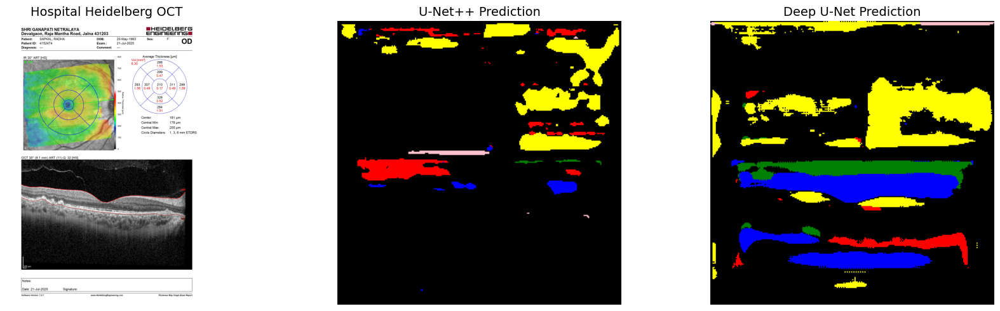

In [ ]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.imshow(hospital_image)
plt.title("Hospital Heidelberg OCT", fontsize=14)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    unetpp_prediction,
    cmap=amd_cmap,
    vmin=0,
    vmax=5
)
plt.title("U-Net++ Prediction", fontsize=14)
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    deep_prediction,
    cmap=amd_cmap,
    vmin=0,
    vmax=5
)
plt.title("Deep U-Net Prediction", fontsize=14)
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
from PIL import Image
import pandas as pd

BASE = "/content/drive/MyDrive/Amd"

EXTRACTED_FOLDERS = [
    "Extracted_jpg_oct_topcon_type_1",
    "Extracted_jpg_oct_topcon_type_2"
]

records = []

for folder in EXTRACTED_FOLDERS:

    folder_path = os.path.join(BASE, folder)

    print("\n" + "="*60)
    print(folder)

    files = os.listdir(folder_path)

    for f in files:

        path = os.path.join(folder_path, f)

        try:
            img = Image.open(path)

            records.append({
                "Folder": folder,
                "File": f,
                "Width": img.width,
                "Height": img.height,
                "Mode": img.mode
            })

        except:
            pass

hospital_df = pd.DataFrame(records)

print("\n========== SUMMARY ==========")
display(hospital_df)


Extracted_jpg_oct_topcon_type_1

Extracted_jpg_oct_topcon_type_2

========== SUMMARY ==========


""


In [ ]:
import os
from PIL import Image
import pandas as pd

BASE = "/content/drive/MyDrive/Amd"

EXTRACTED_FOLDERS = [
    "Extracted_jpg_oct_topcon_type_1",
    "Extracted_jpg_oct_topcon_type_2"
]

records = []

for folder in EXTRACTED_FOLDERS:

    root_folder = os.path.join(BASE, folder)

    print("\n" + "="*70)
    print("FOLDER:", folder)

    for root, dirs, files in os.walk(root_folder):

        for f in files:

            path = os.path.join(root, f)

            try:
                img = Image.open(path)

                records.append({
                    "Folder": folder,
                    "File": f,
                    "FullPath": path,
                    "Width": img.width,
                    "Height": img.height,
                    "Mode": img.mode
                })

            except:
                pass

hospital_df = pd.DataFrame(records)

print("\n========== TOTAL ==========")
print("Readable images:", len(hospital_df))

display(hospital_df.head(20))


FOLDER: Extracted_jpg_oct_topcon_type_1

FOLDER: Extracted_jpg_oct_topcon_type_2

========== TOTAL ==========
Readable images: 5436


,Folder,File,FullPath,Width,Height,Mode
0,Extracted_jpg_oct_topcon_type_1,1003826314_717292_20210222_161605_OCTReport_L_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,408,416,RGB
1,Extracted_jpg_oct_topcon_type_1,1009124677_791872_20211123_161147_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,408,416,RGB
2,Extracted_jpg_oct_topcon_type_1,1010733363_711977_20210203_160919_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,408,416,RGB
3,Extracted_jpg_oct_topcon_type_1,1016064918_751664_20191001_171047_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,408,416,RGB
4,Extracted_jpg_oct_topcon_type_1,1021910591_757035_20190820_143210_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,408,416,RGB
5,Extracted_jpg_oct_topcon_type_1,1023435891_848137_20230328_102559_OCTReport_L_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,408,416,RGB
6,Extracted_jpg_oct_topcon_type_1,1029842317_707747_20200110_122933_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,408,416,RGB
7,Extracted_jpg_oct_topcon_type_1,103086970_868314_20231109_122922_OCTReport_L_0...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,408,416,RGB
8,Extracted_jpg_oct_topcon_type_1,1042898569_236652_20241202_122459_OCTReport_L_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,408,416,RGB
9,Extracted_jpg_oct_topcon_type_1,1051259868_6213_20240301_172617_OCTReport_L_00...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,408,416,RGB


In [ ]:
print("\n========== SUBFOLDERS ==========")

for folder in EXTRACTED_FOLDERS:

    root_folder = os.path.join(BASE, folder)

    print("\n", folder)

    for root, dirs, files in os.walk(root_folder):

        level = root.replace(root_folder, "").count(os.sep)
        indent = "  " * level

        print(indent + os.path.basename(root) + "/")

        for f in files[:5]:
            print(indent + "  " + f)


========== SUBFOLDERS ==========

 Extracted_jpg_oct_topcon_type_1
Extracted_jpg_oct_topcon_type_1/
  processing_log.csv
  raw/
    fundus/
      1003826314_717292_20210222_161605_OCTReport_L_001_fundus_raw.jpg
      1009124677_791872_20211123_161147_OCTReport_R_001_fundus_raw.jpg
      1010733363_711977_20210203_160919_OCTReport_R_001_fundus_raw.jpg
      1016064918_751664_20191001_171047_OCTReport_R_001_fundus_raw.jpg
      1021910591_757035_20190820_143210_OCTReport_R_001_fundus_raw.jpg
    large_oct/
      1003826314_717292_20210222_161605_OCTReport_L_001_OCT_01_raw.jpg
      1003826314_717292_20210222_161605_OCTReport_L_001_OCT_07_raw.jpg
      1009124677_791872_20211123_161147_OCTReport_R_001_OCT_01_raw.jpg
      1009124677_791872_20211123_161147_OCTReport_R_001_OCT_07_raw.jpg
      1010733363_711977_20210203_160919_OCTReport_R_001_OCT_01_raw.jpg
    small_oct/
      1023435891_848137_20230328_102559_OCTReport_L_001_OCT_thumbnail_09_raw.jpg
      1029842317_707747_20200110_12293

In [ ]:
import os
from PIL import Image
import pandas as pd

BASE = "/content/drive/MyDrive/Amd"

EXTRACTED_FOLDERS = [
    "Extracted_jpg_oct_topcon_type_1",
    "Extracted_jpg_oct_topcon_type_2"
]

hospital_records = []

for source in EXTRACTED_FOLDERS:

    source_path = os.path.join(BASE, source)

    print("\n" + "="*70)
    print(source)

    for root, dirs, files in os.walk(source_path):

        parts = [
            p.lower()
            for p in root.replace("\\", "/").split("/")
        ]

        # Must contain either cleaned or uncleaned/raw
        is_cleaned = "cleaned" in parts
        is_uncleaned = "uncleaned" in parts or "raw" in parts

        if not (is_cleaned or is_uncleaned):
            continue

        # ONLY large_oct or small_oct
        if "large_oct" in parts:
            oct_type = "large_oct"

        elif "small_oct" in parts:
            oct_type = "small_oct"

        else:
            continue

        # Ignore fundus automatically
        if "fundus" in parts:
            continue

        condition = (
            "cleaned" if is_cleaned
            else "uncleaned/raw"
        )

        for filename in files:

            path = os.path.join(root, filename)

            try:
                img = Image.open(path)

                hospital_records.append({
                    "Source": source,
                    "Condition": condition,
                    "Type": oct_type,
                    "File": filename,
                    "FullPath": path,
                    "Width": img.width,
                    "Height": img.height,
                    "Mode": img.mode
                })

            except:
                pass


hospital_df = pd.DataFrame(hospital_records)

print("\n==============================================")
print("TOTAL SELECTED HOSPITAL OCT IMAGES:",
      len(hospital_df))
print("==============================================")

display(hospital_df.head(20))


Extracted_jpg_oct_topcon_type_1

Extracted_jpg_oct_topcon_type_2

TOTAL SELECTED HOSPITAL OCT IMAGES: 4530


,Source,Condition,Type,File,FullPath,Width,Height,Mode
0,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1003826314_717292_20210222_161605_OCTReport_L_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,535,416,RGB
1,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1003826314_717292_20210222_161605_OCTReport_L_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,535,416,RGB
2,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1009124677_791872_20211123_161147_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,535,416,RGB
3,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1009124677_791872_20211123_161147_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,535,416,RGB
4,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1010733363_711977_20210203_160919_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,535,416,RGB
5,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1010733363_711977_20210203_160919_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,535,416,RGB
6,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1016064918_751664_20191001_171047_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,535,416,RGB
7,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1016064918_751664_20191001_171047_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,535,416,RGB
8,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1021910591_757035_20190820_143210_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,535,416,RGB
9,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1021910591_757035_20190820_143210_OCTReport_R_...,/content/drive/MyDrive/Amd/Extracted_jpg_oct_t...,535,416,RGB


In [ ]:
if len(hospital_df) > 0:

    display(
        hospital_df
        .groupby(["Source", "Condition", "Type"])
        .size()
        .reset_index(name="Image_Count")
    )

else:

    print("NO OCT IMAGES FOUND")

,Source,Condition,Type,Image_Count
0,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,678
1,Extracted_jpg_oct_topcon_type_1,cleaned,small_oct,1017
2,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,678
3,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,small_oct,1017
4,Extracted_jpg_oct_topcon_type_2,cleaned,large_oct,228
5,Extracted_jpg_oct_topcon_type_2,cleaned,small_oct,342
6,Extracted_jpg_oct_topcon_type_2,uncleaned/raw,large_oct,228
7,Extracted_jpg_oct_topcon_type_2,uncleaned/raw,small_oct,342


Images selected for visual inspection:


,Source,Condition,Type,File,Width,Height
0,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,1003826314_717292_20210222_161605_OCTReport_L_...,535,416
1,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,small_oct,1023435891_848137_20230328_102559_OCTReport_L_...,162,123
2,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1003826314_717292_20210222_161605_OCTReport_L_...,535,416
3,Extracted_jpg_oct_topcon_type_1,cleaned,small_oct,1023435891_848137_20230328_102559_OCTReport_L_...,162,123
4,Extracted_jpg_oct_topcon_type_2,uncleaned/raw,large_oct,1008306724_767743_20191230_165354_OCTReport_N_...,340,257
5,Extracted_jpg_oct_topcon_type_2,uncleaned/raw,small_oct,1008306724_767743_20191230_165354_OCTReport_N_...,102,83
6,Extracted_jpg_oct_topcon_type_2,cleaned,large_oct,1008306724_767743_20191230_165354_OCTReport_N_...,340,257
7,Extracted_jpg_oct_topcon_type_2,cleaned,small_oct,1008306724_767743_20191230_165354_OCTReport_N_...,102,83


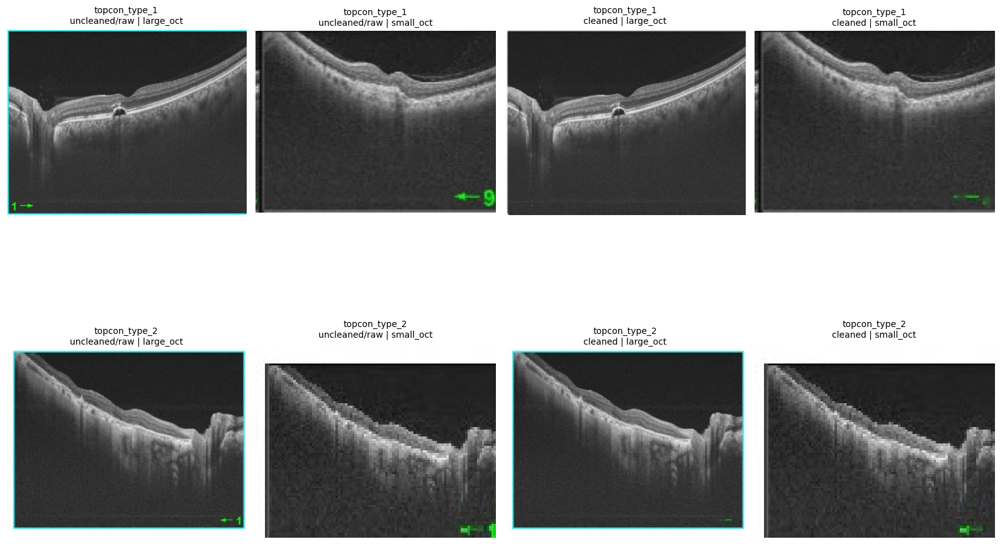

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Pick one image from each Source + Condition + Type
sample_df = (
    hospital_df
    .groupby(["Source", "Condition", "Type"], group_keys=False)
    .head(1)
    .reset_index(drop=True)
)

print("Images selected for visual inspection:")
display(
    sample_df[
        ["Source", "Condition", "Type", "File", "Width", "Height"]
    ]
)

plt.figure(figsize=(16, 12))

for i, (_, row) in enumerate(sample_df.iterrows()):

    img = Image.open(row["FullPath"]).convert("RGB")

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(
        f"{row['Source'].replace('Extracted_jpg_oct_', '')}\n"
        f"{row['Condition']} | {row['Type']}",
        fontsize=10
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("Unique image sizes:")
display(
    hospital_df
    .groupby(["Source", "Condition", "Type", "Width", "Height"])
    .size()
    .reset_index(name="Count")
)

Unique image sizes:


,Source,Condition,Type,Width,Height,Count
0,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,411,319,76
1,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,411,320,76
2,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,535,416,526
3,Extracted_jpg_oct_topcon_type_1,cleaned,small_oct,123,95,76
4,Extracted_jpg_oct_topcon_type_1,cleaned,small_oct,124,95,76
5,Extracted_jpg_oct_topcon_type_1,cleaned,small_oct,124,96,76
6,Extracted_jpg_oct_topcon_type_1,cleaned,small_oct,161,124,263
7,Extracted_jpg_oct_topcon_type_1,cleaned,small_oct,161,125,263
8,Extracted_jpg_oct_topcon_type_1,cleaned,small_oct,162,123,263
9,Extracted_jpg_oct_topcon_type_1,uncleaned/raw,large_oct,411,319,76


In [ ]:
import torch
import numpy as np
from PIL import Image

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

unetpp.eval()
deep_unet.eval()

print("Device:", device)

Device: cuda


In [ ]:
def predict_hospital_image(model, image_path):

    image = Image.open(image_path).convert("RGB")
    original_size = image.size

    image_np = np.array(image)

    # Use the SAME validation preprocessing used during testing
    transformed = val_transform(
        image=image_np
    )

    input_tensor = transformed["image"].unsqueeze(0).to(device)

    with torch.no_grad():

        output = model(input_tensor)

        prediction = torch.argmax(
            output,
            dim=1
        ).squeeze(0).cpu().numpy()

    return image_np, prediction, original_size

In [ ]:
from matplotlib.colors import ListedColormap

amd_colors = [
    "black",   # 0 Background
    "red",     # 1 SRF
    "blue",    # 2 PED
    "green",   # 3 IRF
    "yellow",  # 4 SHRM
    "pink"     # 5 IS/OS
]

amd_cmap = ListedColormap(amd_colors)

Testing image:
/content/drive/MyDrive/Amd/Extracted_jpg_oct_topcon_type_1/raw/large_oct/1003826314_717292_20210222_161605_OCTReport_L_001_OCT_01_raw.jpg


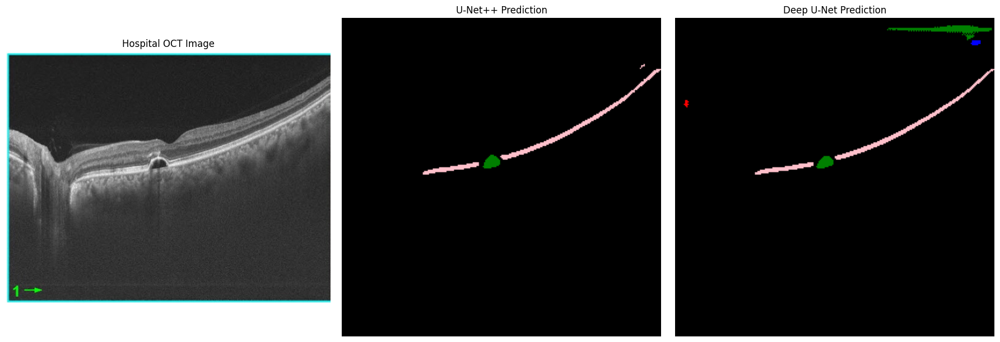

In [ ]:
test_row = hospital_df.iloc[0]

print("Testing image:")
print(test_row["FullPath"])

image_np, unetpp_prediction, original_size = predict_hospital_image(
    unetpp,
    test_row["FullPath"]
)

_, deep_unet_prediction, _ = predict_hospital_image(
    deep_unet,
    test_row["FullPath"]
)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.title("Hospital OCT Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    unetpp_prediction,
    cmap=amd_cmap,
    vmin=0,
    vmax=5
)
plt.title("U-Net++ Prediction")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    deep_unet_prediction,
    cmap=amd_cmap,
    vmin=0,
    vmax=5
)
plt.title("Deep U-Net Prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ONLY CLEANED HOSPITAL OCT IMAGES
cleaned_df = hospital_df[
    hospital_df["Condition"] == "cleaned"
].reset_index(drop=True)

print("Cleaned OCT images:", len(cleaned_df))

display(
    cleaned_df[
        ["Source", "Condition", "Type", "File",
         "Width", "Height"]
    ].head(10)
)

Cleaned OCT images: 2265


,Source,Condition,Type,File,Width,Height
0,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1003826314_717292_20210222_161605_OCTReport_L_...,535,416
1,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1003826314_717292_20210222_161605_OCTReport_L_...,535,416
2,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1009124677_791872_20211123_161147_OCTReport_R_...,535,416
3,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1009124677_791872_20211123_161147_OCTReport_R_...,535,416
4,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1010733363_711977_20210203_160919_OCTReport_R_...,535,416
5,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1010733363_711977_20210203_160919_OCTReport_R_...,535,416
6,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1016064918_751664_20191001_171047_OCTReport_R_...,535,416
7,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1016064918_751664_20191001_171047_OCTReport_R_...,535,416
8,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1021910591_757035_20190820_143210_OCTReport_R_...,535,416
9,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1021910591_757035_20190820_143210_OCTReport_R_...,535,416


In [ ]:
# Select the first CLEANED image
test_row = cleaned_df.iloc[0]

print("Testing CLEANED image:")
print(test_row["FullPath"])

Testing CLEANED image:
/content/drive/MyDrive/Amd/Extracted_jpg_oct_topcon_type_1/cleaned/large_oct/1003826314_717292_20210222_161605_OCTReport_L_001_OCT_01_clean.jpg


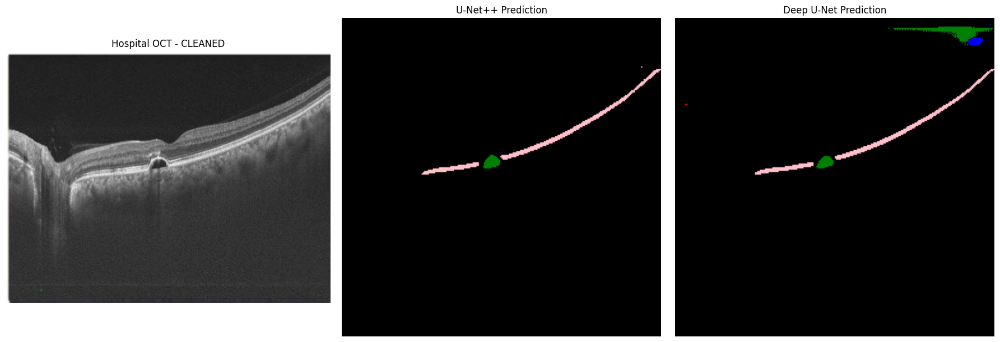

In [ ]:
image_np, unetpp_prediction, original_size = predict_hospital_image(
    unetpp,
    test_row["FullPath"]
)

_, deep_unet_prediction, _ = predict_hospital_image(
    deep_unet,
    test_row["FullPath"]
)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.title("Hospital OCT - CLEANED")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    unetpp_prediction,
    cmap=amd_cmap,
    vmin=0,
    vmax=5
)
plt.title("U-Net++ Prediction")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    deep_unet_prediction,
    cmap=amd_cmap,
    vmin=0,
    vmax=5
)
plt.title("Deep U-Net Prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Select 8 CLEANED hospital OCT images
sample_cleaned = (
    cleaned_df
    .sample(min(8, len(cleaned_df)), random_state=42)
    .reset_index(drop=True)
)

print("Testing", len(sample_cleaned), "cleaned hospital OCT images")

Testing 8 cleaned hospital OCT images


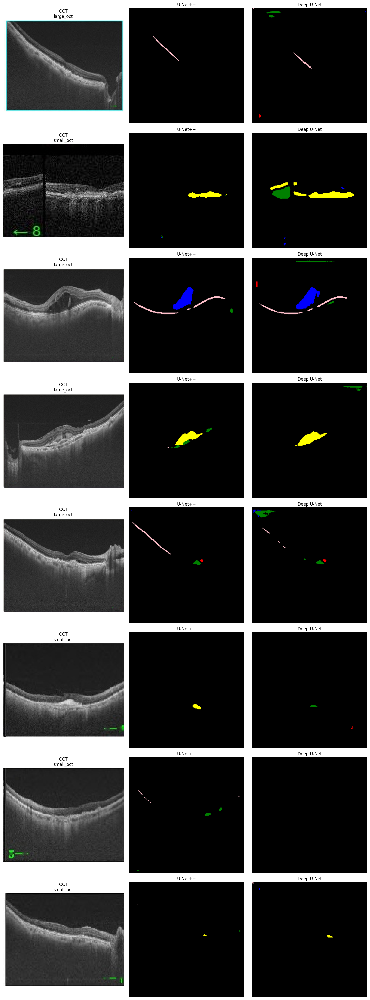

In [ ]:
fig, axes = plt.subplots(
    len(sample_cleaned),
    3,
    figsize=(15, 5 * len(sample_cleaned))
)

if len(sample_cleaned) == 1:
    axes = np.expand_dims(axes, axis=0)

for i, (_, row) in enumerate(sample_cleaned.iterrows()):

    image_np, unetpp_pred, _ = predict_hospital_image(
        unetpp,
        row["FullPath"]
    )

    _, deep_pred, _ = predict_hospital_image(
        deep_unet,
        row["FullPath"]
    )

    axes[i, 0].imshow(image_np)
    axes[i, 0].set_title(
        f"OCT\n{row['Type']}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        unetpp_pred,
        cmap=amd_cmap,
        vmin=0,
        vmax=5
    )
    axes[i, 1].set_title("U-Net++")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(
        deep_pred,
        cmap=amd_cmap,
        vmin=0,
        vmax=5
    )
    axes[i, 2].set_title("Deep U-Net")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import numpy as np
import pandas as pd
from PIL import Image

def calculate_image_quality(path):

    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        return 0, 0, 0

    # Sharpness
    sharpness = cv2.Laplacian(
        img,
        cv2.CV_64F
    ).var()

    # Contrast
    contrast = img.std()

    # Average brightness
    brightness = img.mean()

    return sharpness, contrast, brightness


quality_records = []

for _, row in cleaned_df.iterrows():

    sharpness, contrast, brightness = calculate_image_quality(
        row["FullPath"]
    )

    quality_records.append({
        "FullPath": row["FullPath"],
        "Source": row["Source"],
        "Condition": row["Condition"],
        "Type": row["Type"],
        "File": row["File"],
        "Sharpness": sharpness,
        "Contrast": contrast,
        "Brightness": brightness
    })


quality_df = pd.DataFrame(quality_records)

print("Total cleaned images:", len(quality_df))

display(
    quality_df[
        ["Source", "Type", "File",
         "Sharpness", "Contrast", "Brightness"]
    ].head(10)
)

Total cleaned images: 2265


,Source,Type,File,Sharpness,Contrast,Brightness
0,Extracted_jpg_oct_topcon_type_1,large_oct,1003826314_717292_20210222_161605_OCTReport_L_...,257.592359,43.801246,65.867043
1,Extracted_jpg_oct_topcon_type_1,large_oct,1003826314_717292_20210222_161605_OCTReport_L_...,244.305716,43.923789,65.394599
2,Extracted_jpg_oct_topcon_type_1,large_oct,1009124677_791872_20211123_161147_OCTReport_R_...,4028.269668,34.669449,66.791872
3,Extracted_jpg_oct_topcon_type_1,large_oct,1009124677_791872_20211123_161147_OCTReport_R_...,2903.879921,35.214330,62.482216
4,Extracted_jpg_oct_topcon_type_1,large_oct,1010733363_711977_20210203_160919_OCTReport_R_...,339.345094,43.520250,65.233582
5,Extracted_jpg_oct_topcon_type_1,large_oct,1010733363_711977_20210203_160919_OCTReport_R_...,252.627395,42.445292,68.092869
6,Extracted_jpg_oct_topcon_type_1,large_oct,1016064918_751664_20191001_171047_OCTReport_R_...,235.460498,44.126940,62.162621
7,Extracted_jpg_oct_topcon_type_1,large_oct,1016064918_751664_20191001_171047_OCTReport_R_...,295.503382,45.623418,64.589616
8,Extracted_jpg_oct_topcon_type_1,large_oct,1021910591_757035_20190820_143210_OCTReport_R_...,485.749556,38.931077,61.917824
9,Extracted_jpg_oct_topcon_type_1,large_oct,1021910591_757035_20190820_143210_OCTReport_R_...,385.540630,40.557758,61.958020


In [ ]:
print("Sharpness statistics:")
print(
    quality_df["Sharpness"].describe(
        percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    )
)


Sharpness statistics:
count     2265.000000
mean      1548.407228
std       1515.270684
min          0.000000
5%         249.452561
10%        275.454135
25%        463.631477
50%       1326.673640
75%       2057.340695
90%       3497.164894
95%       3858.374647
max      21166.232406
Name: Sharpness, dtype: float64


In [ ]:
sharpness_threshold = quality_df["Sharpness"].quantile(0.15)
contrast_threshold = quality_df["Contrast"].quantile(0.10)

print("Sharpness threshold:", sharpness_threshold)
print("Contrast threshold:", contrast_threshold)

Sharpness threshold: 315.27288792370734
Contrast threshold: 31.20928516097126


In [ ]:
good_quality_df = quality_df[
    (quality_df["Sharpness"] >= sharpness_threshold) &
    (quality_df["Contrast"] >= contrast_threshold) &
    (quality_df["Brightness"] >= 20) &
    (quality_df["Brightness"] <= 240)
].copy()

good_quality_df = good_quality_df.reset_index(drop=True)

print("Original cleaned images:", len(quality_df))
print("Good-quality images:", len(good_quality_df))
print("Excluded images:",
      len(quality_df) - len(good_quality_df))

Original cleaned images: 2265
Good-quality images: 1698
Excluded images: 567


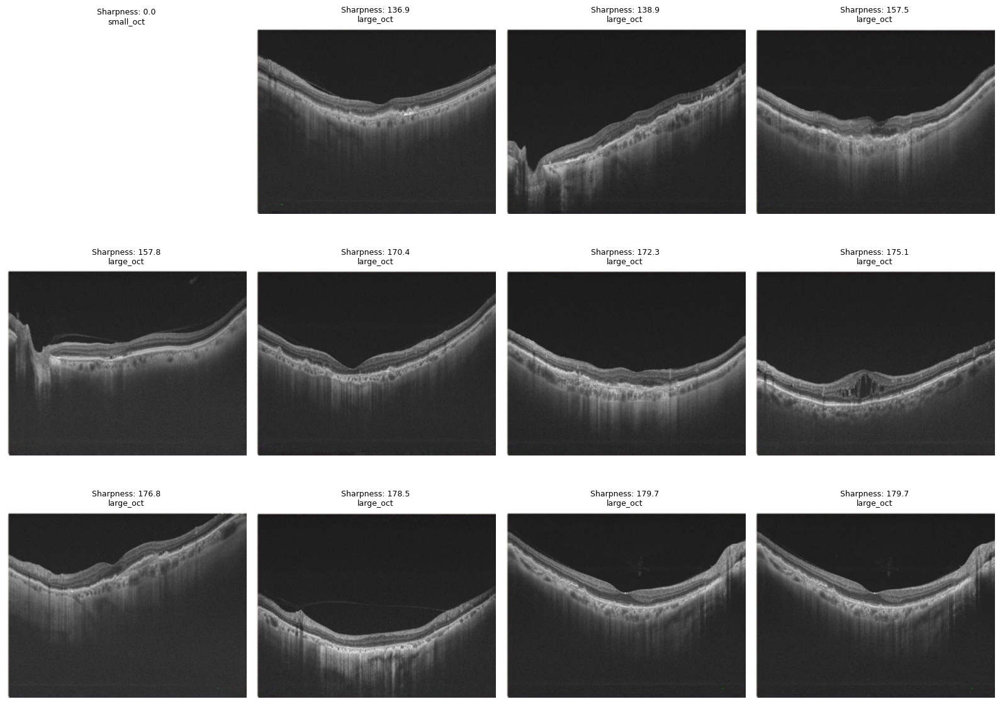

In [ ]:
worst = (
    quality_df
    .sort_values("Sharpness")
    .head(12)
)

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 12))

for i, (_, row) in enumerate(worst.iterrows()):

    img = Image.open(row["FullPath"]).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(
        f"Sharpness: {row['Sharpness']:.1f}\n"
        f"{row['Type']}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("FINAL HOSPITAL DATASET")
print("======================")
print("Total good-quality OCT images:", len(good_quality_df))

display(
    good_quality_df[
        ["Source", "Condition", "Type", "File",
         "Sharpness", "Contrast", "Brightness"]
    ].head(10)
)

FINAL HOSPITAL DATASET
Total good-quality OCT images: 1698


,Source,Condition,Type,File,Sharpness,Contrast,Brightness
0,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1009124677_791872_20211123_161147_OCTReport_R_...,4028.269668,34.669449,66.791872
1,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1009124677_791872_20211123_161147_OCTReport_R_...,2903.879921,35.214330,62.482216
2,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1010733363_711977_20210203_160919_OCTReport_R_...,339.345094,43.520250,65.233582
3,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1021910591_757035_20190820_143210_OCTReport_R_...,485.749556,38.931077,61.917824
4,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1021910591_757035_20190820_143210_OCTReport_R_...,385.540630,40.557758,61.958020
5,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1042898569_236652_20241202_122459_OCTReport_L_...,348.103426,42.161758,62.120844
6,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1051259868_6213_20240301_172617_OCTReport_L_00...,419.384233,41.137818,66.396545
7,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1052422094_736015_20190918_125007_OCTReport_L_...,353.992040,40.703384,61.755050
8,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1052422094_736015_20190918_125007_OCTReport_L_...,439.568890,43.918653,66.041355
9,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,1082439799_737769_22082024_100131_OCTReport_R_...,2397.307914,71.877329,50.785493


In [ ]:
display(
    good_quality_df
    .groupby(["Source", "Condition", "Type"])
    .size()
    .reset_index(name="Image_Count")
)

,Source,Condition,Type,Image_Count
0,Extracted_jpg_oct_topcon_type_1,cleaned,large_oct,339
1,Extracted_jpg_oct_topcon_type_1,cleaned,small_oct,827
2,Extracted_jpg_oct_topcon_type_2,cleaned,large_oct,228
3,Extracted_jpg_oct_topcon_type_2,cleaned,small_oct,304


In [ ]:
class HospitalOCTDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = np.array(
            Image.open(row["FullPath"]).convert("RGB")
        )

        if self.transform:
            transformed = self.transform(image=image)
            image = transformed["image"]

        return image, row["FullPath"]

In [ ]:
hospital_transform = A.Compose([
    A.Resize(256, 256),

    A.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    ),

    ToTensorV2()
])

In [ ]:
hospital_dataset = HospitalOCTDataset(
    good_quality_df,
    transform=hospital_transform
)

hospital_loader = DataLoader(
    hospital_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Hospital images ready:", len(hospital_dataset))

Hospital images ready: 1698


In [ ]:
unetpp.eval()
deep_unet.eval()

hospital_predictions = []

with torch.no_grad():

    for images, paths in hospital_loader:

        images = images.to(device)

        unetpp_output = unetpp(images)
        deep_output = deep_unet(images)

        unetpp_pred = torch.argmax(
            unetpp_output,
            dim=1
        ).cpu().numpy()

        deep_pred = torch.argmax(
            deep_output,
            dim=1
        ).cpu().numpy()

        for i in range(len(paths)):

            hospital_predictions.append({
                "path": paths[i],
                "unetpp_prediction": unetpp_pred[i],
                "deep_unet_prediction": deep_pred[i]
            })

print(
    "Predictions generated:",
    len(hospital_predictions)
)

Predictions generated: 1698


In [ ]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt

# AMD-SD official biomarker colors
amd_colors = [
    "black",   # 0 Background
    "red",     # 1 SRF
    "blue",    # 2 PED
    "green",   # 3 IRF
    "yellow",  # 4 SHRM
    "pink"     # 5 IS/OS
]

amd_map = ListedColormap(amd_colors)

print("AMD biomarker color map created successfully.")

AMD biomarker color map created successfully.


In [ ]:
def visualize_hospital_prediction(index=0):

    result = hospital_predictions[index]

    image = np.array(
        Image.open(result["path"]).convert("RGB")
    )

    unet_pred = result["unetpp_prediction"]
    deep_pred = result["deep_unet_prediction"]

    plt.figure(figsize=(18, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title("Hospital OCT")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(unet_pred, cmap=amd_map, vmin=0, vmax=5)
    plt.title("U-Net++ Prediction")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(deep_pred, cmap=amd_map, vmin=0, vmax=5)
    plt.title("Deep U-Net Prediction")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

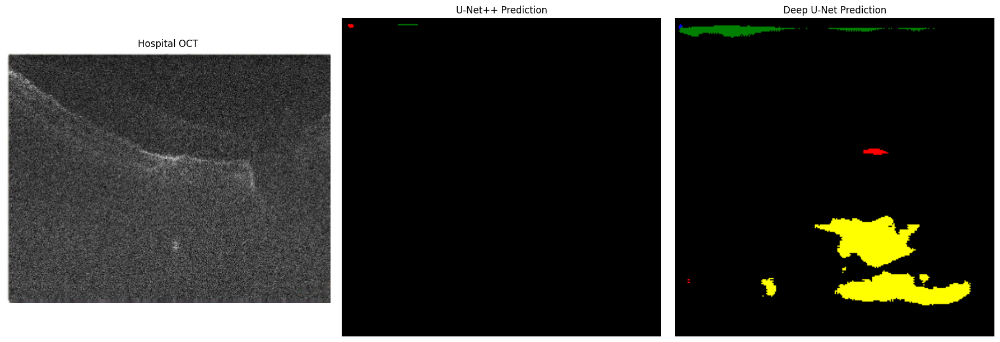

In [ ]:
visualize_hospital_prediction(index=0)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving octtest.png to octtest.png


In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import torch

# --------------------------------------------------
# AMD-SD biomarker colors
# --------------------------------------------------

amd_colors = [
    "black",   # 0 Background
    "red",     # 1 SRF
    "blue",    # 2 PED
    "green",   # 3 IRF
    "yellow",  # 4 SHRM
    "pink"     # 5 IS/OS
]

amd_map = ListedColormap(amd_colors)

# --------------------------------------------------
# Get uploaded image
# --------------------------------------------------

image_path = list(uploaded.keys())[0]

image = np.array(
    Image.open(image_path).convert("RGB")
)

print("Image:", image_path)
print("Original shape:", image.shape)

# --------------------------------------------------
# Same preprocessing used during training
# --------------------------------------------------

transformed = val_transform(image=image)

input_tensor = transformed["image"].unsqueeze(0).to(device)

# --------------------------------------------------
# U-Net++ prediction
# --------------------------------------------------

unetpp.eval()
deep_unet.eval()

with torch.no_grad():

    unetpp_output = unetpp(input_tensor)
    deep_output = deep_unet(input_tensor)

    unetpp_prediction = torch.argmax(
        unetpp_output, dim=1
    )[0].cpu().numpy()

    deep_prediction = torch.argmax(
        deep_output, dim=1
    )[0].cpu().numpy()

# --------------------------------------------------
# Display
# --------------------------------------------------

plt.figure(figsize=(18, 6))

# Original OCT
plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Hospital OCT", fontsize=14)
plt.axis("off")

# U-Net++
plt.subplot(1, 3, 2)
plt.imshow(
    unetpp_prediction,
    cmap=amd_map,
    vmin=0,
    vmax=5
)
plt.title("U-Net++ Prediction", fontsize=14)
plt.axis("off")

# Deep U-Net
plt.subplot(1, 3, 3)
plt.imshow(
    deep_prediction,
    cmap=amd_map,
    vmin=0,
    vmax=5
)
plt.title("Deep U-Net Prediction", fontsize=14)
plt.axis("off")

plt.tight_layout()
plt.show()

Image: octtest.png
Original shape: (613, 1785, 3)


NameError: name 'val_transform' is not defined

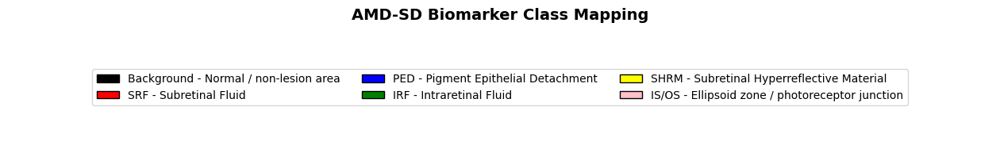

In [ ]:
# ============================================================
# AMD-SD BIOMARKER CLASS MAPPING
# ============================================================

from matplotlib.patches import Patch

biomarker_info = [
    ("Background", "Normal / non-lesion area", "black"),
    ("SRF", "Subretinal Fluid", "red"),
    ("PED", "Pigment Epithelial Detachment", "blue"),
    ("IRF", "Intraretinal Fluid", "green"),
    ("SHRM", "Subretinal Hyperreflective Material", "yellow"),
    ("IS/OS", "Ellipsoid zone / photoreceptor junction", "pink")
]

legend_elements = [
    Patch(
        facecolor=color,
        edgecolor="black",
        label=f"{name} - {meaning}"
    )
    for name, meaning, color in biomarker_info
]

plt.figure(figsize=(16, 2))

plt.legend(
    handles=legend_elements,
    loc="center",
    ncol=3,
    fontsize=10,
    frameon=True
)

plt.axis("off")
plt.title(
    "AMD-SD Biomarker Class Mapping",
    fontsize=14,
    fontweight="bold"
)

plt.show()

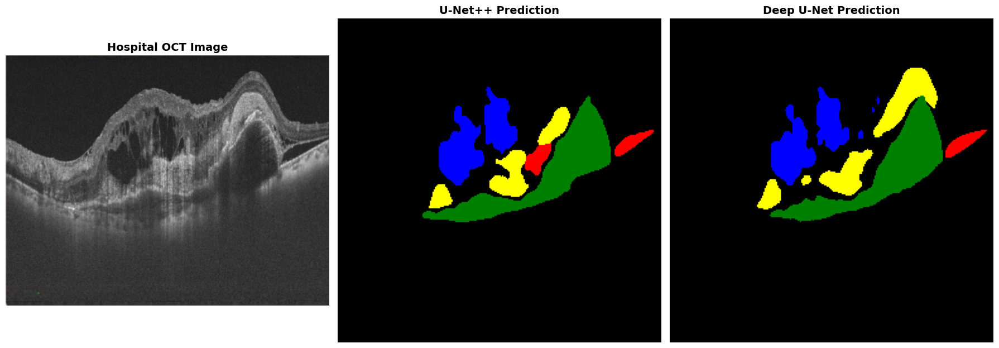

In [ ]:
# ============================================================
# HOSPITAL OCT - MODEL INFERENCE
# ============================================================

plt.figure(figsize=(18, 7))

# Original OCT
plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Hospital OCT Image", fontsize=14, fontweight="bold")
plt.axis("off")

# U-Net++
plt.subplot(1, 3, 2)
plt.imshow(
    unetpp_prediction,
    cmap=amd_map,
    vmin=0,
    vmax=5
)
plt.title("U-Net++ Prediction", fontsize=14, fontweight="bold")
plt.axis("off")

# Deep U-Net
plt.subplot(1, 3, 3)
plt.imshow(
    deep_prediction,
    cmap=amd_map,
    vmin=0,
    vmax=5
)
plt.title("Deep U-Net Prediction", fontsize=14, fontweight="bold")
plt.axis("off")

plt.tight_layout()
plt.show()

This figure shows the external inference results of the two trained segmentation models on an unseen hospital OCT image.
- Left – Hospital OCT Image: The original OCT B-scan from the hospital dataset.
- Middle – U-Net++ Prediction: The segmentation produced by the trained U-Net++ model.
- Right – Deep U-Net Prediction: The segmentation produced by the trained Deep U-Net model.
The predicted colors represent the biomarker classes:
-  Red → SRF (Subretinal Fluid)
-  Blue → PED (Pigment Epithelial Detachment)
-  Green → IRF (Intraretinal Fluid)
-  Yellow → SHRM (Subretinal Hyperreflective Material)
-  Pink → IS/OS (Ellipsoid zone / photoreceptor junction)
-  Black → Background

What this result shows
Both models identify several retinal structures and produce similar overall segmentation patterns, but the exact shape and extent of the predicted regions differ.
- U-Net++ produces more localized blue, yellow, green and red regions.
- Deep U-Net produces a somewhat broader segmentation, particularly in the yellow and green regions.

- These differences demonstrate that the two architectures learn and segment the retinal structures differently when applied to an unseen hospital OCT image.


Important: Since this hospital image does not have an expert-annotated ground-truth mask, these colored regions represent model predictions, not clinically confirmed biomarker diagnoses. Therefore, Dice/IoU cannot be calculated for this particular image.

In [ ]:
# ============================================================
# BIOMARKERS DETECTED BY EACH MODEL
# ============================================================

CLASS_NAMES = [
    "Background",
    "SRF",
    "PED",
    "IRF",
    "SHRM",
    "IS/OS"
]

def detected_biomarkers(prediction):

    detected = []

    for class_id in range(1, 6):

        if np.any(prediction == class_id):
            detected.append(CLASS_NAMES[class_id])

    return detected


unetpp_detected = detected_biomarkers(unetpp_prediction)
deep_detected = detected_biomarkers(deep_prediction)

print("======================================")
print("HOSPITAL OCT BIOMARKER INFERENCE")
print("======================================")

print("\nU-Net++ detected:")
for biomarker in unetpp_detected:
    print("✓", biomarker)

print("\nDeep U-Net detected:")
for biomarker in deep_detected:
    print("✓", biomarker)

HOSPITAL OCT BIOMARKER INFERENCE

U-Net++ detected:
✓ SRF
✓ PED
✓ IRF
✓ SHRM

Deep U-Net detected:
✓ SRF
✓ PED
✓ IRF
✓ SHRM


In [ ]:
# ============================================================
# BIOMARKER PIXEL PERCENTAGE
# ============================================================

def biomarker_percentages(prediction):

    total_pixels = prediction.size

    results = {}

    for class_id in range(1, 6):

        pixel_count = np.sum(prediction == class_id)

        percentage = (
            pixel_count / total_pixels
        ) * 100

        results[CLASS_NAMES[class_id]] = percentage

    return results


unetpp_percentages = biomarker_percentages(
    unetpp_prediction
)

deep_percentages = biomarker_percentages(
    deep_prediction
)


print("======================================")
print("BIOMARKER AREA (%)")
print("======================================")

print("\nU-Net++:")
for biomarker, percentage in unetpp_percentages.items():
    print(f"{biomarker:8s}: {percentage:.2f}%")

print("\nDeep U-Net:")
for biomarker, percentage in deep_percentages.items():
    print(f"{biomarker:8s}: {percentage:.2f}%")

BIOMARKER AREA (%)

U-Net++:
SRF     : 0.86%
PED     : 3.25%
IRF     : 5.34%
SHRM    : 2.07%
IS/OS   : 0.00%

Deep U-Net:
SRF     : 0.45%
PED     : 3.17%
IRF     : 5.23%
SHRM    : 3.38%
IS/OS   : 0.00%


In [ ]:
import os

print("U-Net++ model:", "unetpp" in globals())
print("Deep U-Net model:", "deep_unet" in globals())
print("U-Net++ history:", "unetpp_history" in globals())
print("Deep U-Net history:", "deep_unet_history" in globals())

print("\nCheckpoint files:")
for f in os.listdir("/content"):
    if f.endswith((".pth", ".pt", ".ckpt")):
        print(f)

U-Net++ model: False
Deep U-Net model: False
U-Net++ history: False
Deep U-Net history: False

Checkpoint files:


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

search_root = '/content/drive/MyDrive'
extensions = ('.pth', '.pt', '.ckpt', '.h5', '.keras')

print("Searching Google Drive for model checkpoints...")

for root, dirs, files in os.walk(search_root):
    # Skip common folders that can make the search unnecessarily slow
    dirs[:] = [
        d for d in dirs
        if d not in ['.git', 'node_modules', '.cache']
    ]

    for file in files:
        if file.lower().endswith(extensions):
            print(os.path.join(root, file))

Mounted at /content/drive
Searching Google Drive for model checkpoints...
/content/drive/MyDrive/MANet_AMD_Project/MANet_AMD_best.keras
/content/drive/MyDrive/MANet_AMD_Project/MANet_AMD_weights.h5
/content/drive/MyDrive/MANet_AMD_Project/MANet_AMD_trained.weights.h5
/content/drive/MyDrive/MANet_AMD_Project/MANet_AMD_portable.keras
/content/drive/MyDrive/AMD_LinkNet_Model/linknet_best.pth
/content/drive/MyDrive/AMD_LinkNet_Model/linknet_latest.pth
/content/drive/MyDrive/AMD_UNet_Model/unet_best.pth
/content/drive/MyDrive/AMD_UNet_Model/unet_latest.pth


In [ ]:
# AMD Project: Recovery Check
# Run after the existing imports, dataset setup,
# model definitions, and data-loader cells.

import os
import torch

print("=" * 55)
print("AMD PROJECT - CURRENT RUNTIME STATUS")
print("=" * 55)

names_to_check = [
    "unetpp",
    "deep_unet",
    "train_loader",
    "val_loader",
    "test_loader",
    "unetpp_history",
    "deep_unet_history",
    "CLASS_NAMES",
    "amd_map"
]

for name in names_to_check:
    print(f"{name:22s}: {'Available' if name in globals() else 'Not available'}")

print("\nSaved AMD model files:")

folders = [
    "/content/drive/MyDrive/AMD_UNet_Model",
    "/content/drive/MyDrive/AMD_LinkNet_Model",
    "/content/drive/MyDrive/MANet_AMD_Project"
]

for folder in folders:
    if os.path.isdir(folder):
        for filename in os.listdir(folder):
            if filename.endswith((".pth", ".pt", ".keras", ".h5")):
                print(os.path.join(folder, filename))

AMD PROJECT - CURRENT RUNTIME STATUS
unetpp                : Not available
deep_unet             : Not available
train_loader          : Not available
val_loader            : Not available
test_loader           : Not available
unetpp_history        : Not available
deep_unet_history     : Not available
CLASS_NAMES           : Not available
amd_map               : Not available

Saved AMD model files:
/content/drive/MyDrive/AMD_UNet_Model/unet_best.pth
/content/drive/MyDrive/AMD_UNet_Model/unet_latest.pth
/content/drive/MyDrive/AMD_LinkNet_Model/linknet_best.pth
/content/drive/MyDrive/AMD_LinkNet_Model/linknet_latest.pth
/content/drive/MyDrive/MANet_AMD_Project/MANet_AMD_best.keras
/content/drive/MyDrive/MANet_AMD_Project/MANet_AMD_weights.h5
/content/drive/MyDrive/MANet_AMD_Project/MANet_AMD_trained.weights.h5
/content/drive/MyDrive/MANet_AMD_Project/MANet_AMD_portable.keras


In [ ]:
# Check the restored AMD project setup

names = [
    "CLASS_NAMES",
    "unetpp",
    "deep_unet",
    "train_loader",
    "val_loader",
    "test_loader",
]

for name in names:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

CLASS_NAMES: Missing
unetpp: Missing
deep_unet: Missing
train_loader: Missing
val_loader: Missing
test_loader: Missing


## FINAL CELL — Load saved models and overlay biomarkers on the OCT image

**Run this after the imports, model architecture cells, preprocessing (`val_transform`), and hospital image indexing cells. Do not rerun the training cells.** This cell searches Drive for the saved `.pth` checkpoints, loads them into the already-defined model architectures, and plots the biomarker masks transparently over the original OCT image.

If multiple checkpoint files with the same name are found, inspect the printed paths and set `UNETPP_CHECKPOINT` / `DEEPUNET_CHECKPOINT` manually to the intended files before proceeding.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully loaded: /content/drive/MyDrive/AMD_Segmentation_Models/best_unetpp.pth
Successfully loaded: /content/drive/MyDrive/AMD_Segmentation_Models/best_deep_unet.pth
Number of OCT images: 678
Selected image: /content/drive/MyDrive/Amd/Extracted_jpg_oct_topcon_type_1/cleaned/large_oct/1003826314_717292_20210222_161605_OCTReport_L_001_OCT_01_clean.jpg
Original image dimensions: (416, 535, 3)


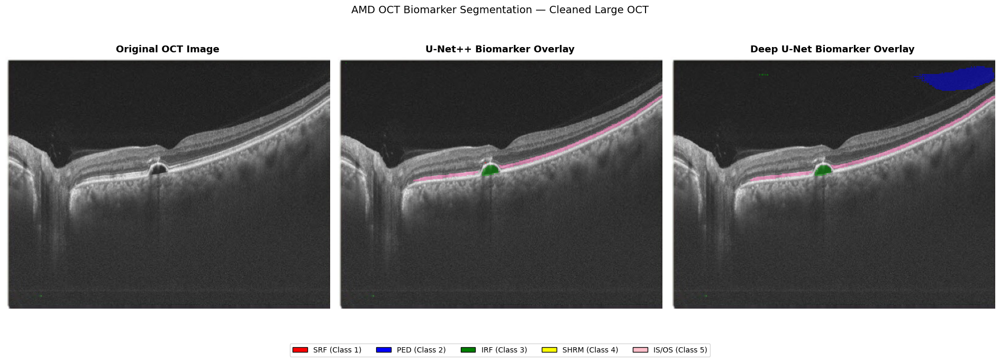


Predicted classes in U-Net++: [0 1 3 5]
Predicted classes in Deep U-Net: [0 2 3 5]

Color mapping:
Class 0: Background — black
Class 1: SRF — red
Class 2: PED — blue
Class 3: IRF — green
Class 4: SHRM — yellow
Class 5: IS/OS — pink

Note: These are model predictions. They are not confirmed diagnoses or expert ground-truth annotations.


In [4]:

# ============================================================
# AMD OCT: TRANSPARENT BIOMARKER OVERLAYS
# Source: Amd/Extracted_jpg_oct_topcon_type_1/cleaned/large_oct
# Loads saved checkpoints. NO TRAINING IS PERFORMED.
# ============================================================

!pip -q install segmentation-models-pytorch albumentations

import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from google.colab import drive
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

drive.mount('/content/drive', force_remount=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 6
IMAGE_SIZE = 256

# ------------------------------------------------------------
# 1. IMAGE TRANSFORMATION
# Must match preprocessing used during model training.
# ------------------------------------------------------------

val_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.Normalize(mean=(0.5, 0.5, 0.5),
                std=(0.5, 0.5, 0.5)),
    ToTensorV2()
])

# ------------------------------------------------------------
# 2. MODEL ARCHITECTURES
# These must match the architectures used to save checkpoints.
# ------------------------------------------------------------

unetpp = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=NUM_CLASSES
)

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class DeepUNet(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.enc1 = ConvBlock(3, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)
        self.enc5 = ConvBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = ConvBlock(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = ConvBlock(64, 32)

        self.final = nn.Conv2d(32, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        e5 = self.enc5(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(e5), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.final(d1)


deep_unet = DeepUNet(num_classes=NUM_CLASSES)

# ------------------------------------------------------------
# 3. LOAD THE CORRECT SAVED CHECKPOINTS
# ------------------------------------------------------------

MODEL_DIR = "/content/drive/MyDrive/AMD_Segmentation_Models"

UNETPP_CHECKPOINT = os.path.join(MODEL_DIR, "best_unetpp.pth")
DEEPUNET_CHECKPOINT = os.path.join(MODEL_DIR, "best_deep_unet.pth")

for path in [UNETPP_CHECKPOINT, DEEPUNET_CHECKPOINT]:
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Checkpoint not found: {path}\n"
            "Check the actual filenames in your Google Drive."
        )


def load_checkpoint(model, path):
    checkpoint = torch.load(
        path, map_location=device, weights_only=True
    )

    # Support either a raw state_dict or a wrapped checkpoint.
    if isinstance(checkpoint, dict):
        if "model_state_dict" in checkpoint:
            checkpoint = checkpoint["model_state_dict"]
        elif "state_dict" in checkpoint:
            checkpoint = checkpoint["state_dict"]

    # Strict loading prevents silently using mismatched weights.
    model.load_state_dict(checkpoint, strict=True)
    model.to(device)
    model.eval()
    print("Successfully loaded:", path)


load_checkpoint(unetpp, UNETPP_CHECKPOINT)
load_checkpoint(deep_unet, DEEPUNET_CHECKPOINT)

# ------------------------------------------------------------
# 4. SELECT AN IMAGE FROM YOUR EXACT FOLDER
# ------------------------------------------------------------

OCT_DIR = (
    "/content/drive/MyDrive/Amd/"
    "Extracted_jpg_oct_topcon_type_1/"
    "cleaned/large_oct"
)

if not os.path.isdir(OCT_DIR):
    raise FileNotFoundError(
        f"Folder not found: {OCT_DIR}\n"
        "Check whether your actual folder is named "
        "Extracted_jpg_oct_topcon_type_1 or "
        "Extracted_jpg_oct_topcon_type1."
    )

image_paths = sorted([
    os.path.join(OCT_DIR, filename)
    for filename in os.listdir(OCT_DIR)
    if filename.lower().endswith(
        (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")
    )
])

if not image_paths:
    raise FileNotFoundError(
        f"No readable image filenames found in {OCT_DIR}"
    )

print("Number of OCT images:", len(image_paths))

# Change this index to select another image.
IMAGE_INDEX = 0
OCT_PATH = image_paths[IMAGE_INDEX]

original_image = np.array(
    Image.open(OCT_PATH).convert("RGB")
)

print("Selected image:", OCT_PATH)
print("Original image dimensions:", original_image.shape)

# ------------------------------------------------------------
# 5. RUN INFERENCE — NO TRAINING
# ------------------------------------------------------------

transformed = val_transform(image=original_image)
input_tensor = transformed["image"].unsqueeze(0).to(device)

with torch.no_grad():
    unetpp_logits = unetpp(input_tensor)
    deep_logits = deep_unet(input_tensor)

    unetpp_small = (
        unetpp_logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
    )
    deep_small = (
        deep_logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
    )

# Restore mask dimensions for display.
# Nearest-neighbor interpolation preserves class IDs.
orig_h, orig_w = original_image.shape[:2]

unetpp_mask = np.array(
    Image.fromarray(unetpp_small).resize(
        (orig_w, orig_h), Image.Resampling.NEAREST
    )
)
deep_mask = np.array(
    Image.fromarray(deep_small).resize(
        (orig_w, orig_h), Image.Resampling.NEAREST
    )
)

# ------------------------------------------------------------
# 6. BIOMARKER COLOR LEGEND
# ------------------------------------------------------------

biomarker_names = [
    "Background", "SRF", "PED", "IRF", "SHRM", "IS/OS"
]

biomarker_colors = [
    "black",  # Class 0: Background
    "red",    # Class 1: SRF
    "blue",   # Class 2: PED
    "green",  # Class 3: IRF
    "yellow", # Class 4: SHRM
    "pink"    # Class 5: IS/OS
]

# The background is transparent in the overlay.
overlay_cmap = ListedColormap([
    (0, 0, 0, 0),  # Background: transparent
    (1, 0, 0, 1),  # SRF: red
    (0, 0, 1, 1),  # PED: blue
    (0, 0.65, 0, 1),  # IRF: green
    (1, 1, 0, 1),  # SHRM: yellow
    (1, 0.4, 0.7, 1)  # IS/OS: pink
])


def plot_oct_overlay(ax, oct_rgb, mask, title, alpha=0.48):
    # Original OCT stays visible underneath the colored regions.
    ax.imshow(oct_rgb)

    visible_mask = np.ma.masked_where(mask == 0, mask)

    ax.imshow(
        visible_mask,
        cmap=overlay_cmap,
        vmin=0,
        vmax=5,
        alpha=alpha,
        interpolation="nearest"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.axis("off")


# ------------------------------------------------------------
# 7. DISPLAY ORIGINAL OCT + BOTH MODEL OVERLAYS
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(19, 7))

axes[0].imshow(original_image)
axes[0].set_title(
    "Original OCT Image", fontsize=13, fontweight="bold"
)
axes[0].axis("off")

plot_oct_overlay(
    axes[1], original_image, unetpp_mask,
    "U-Net++ Biomarker Overlay"
)

plot_oct_overlay(
    axes[2], original_image, deep_mask,
    "Deep U-Net Biomarker Overlay"
)

legend_handles = [
    Patch(
        facecolor=biomarker_colors[i],
        edgecolor="black",
        label=f"{biomarker_names[i]} (Class {i})"
    )
    for i in range(1, NUM_CLASSES)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    bbox_to_anchor=(0.5, 0.02),
    frameon=True
)

plt.suptitle(
    "AMD OCT Biomarker Segmentation — Cleaned Large OCT",
    fontsize=14
)
plt.tight_layout(rect=[0, 0.12, 1, 0.93])
plt.show()

print("\nPredicted classes in U-Net++:", np.unique(unetpp_mask))
print("Predicted classes in Deep U-Net:", np.unique(deep_mask))
print("\nColor mapping:")
for i in range(NUM_CLASSES):
    print(f"Class {i}: {biomarker_names[i]} — {biomarker_colors[i]}")

print(
    "\nNote: These are model predictions. "
    "They are not confirmed diagnoses or expert ground-truth annotations."
)


Saving 11492172_871195_20230817_115048_OCTReport_L_001_OCT_07_clean.jpg to 11492172_871195_20230817_115048_OCTReport_L_001_OCT_07_clean.jpg
Selected image: 11492172_871195_20230817_115048_OCTReport_L_001_OCT_07_clean.jpg


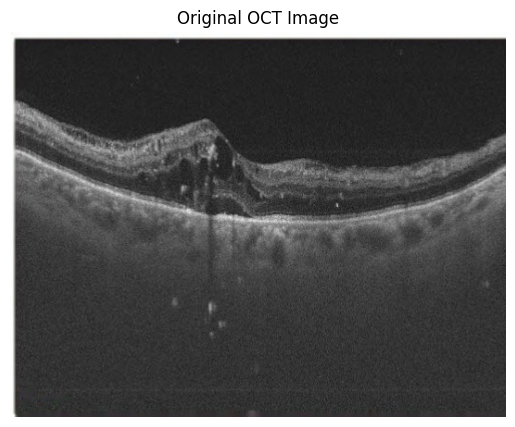

In [8]:
from google.colab import files
from PIL import Image
import io
import matplotlib.pyplot as plt

# Upload the specific OCT image you want to analyze
uploaded = files.upload()

# Get the uploaded image
image_name = next(iter(uploaded))
original_image = Image.open(
    io.BytesIO(uploaded[image_name])
).convert("RGB")

print("Selected image:", image_name)

plt.figure(figsize=(7, 5))
plt.imshow(original_image, cmap="gray")
plt.title("Original OCT Image")
plt.axis("off")
plt.show()

In [11]:

import os
import torch
import segmentation_models_pytorch as smp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Path to your saved U-Net++ checkpoint
UNETPP_CHECKPOINT = (
    "/content/drive/MyDrive/AMD_Segmentation_Models/best_unetpp.pth"
)

if not os.path.exists(UNETPP_CHECKPOINT):
    raise FileNotFoundError(
        f"U-Net++ checkpoint not found: {UNETPP_CHECKPOINT}\n"
        "Check the actual checkpoint location in Google Drive."
    )

# Recreate the same architecture used during training
unetpp_model = smp.UnetPlusPlus(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=6
).to(device)

# Load the trained weights
checkpoint = torch.load(
    UNETPP_CHECKPOINT,
    map_location=device,
    weights_only=True
)

# Support checkpoints saved as either a state dict or a dictionary
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]

# Remove a DataParallel prefix if present
checkpoint = {
    k.removeprefix("module."): v
    for k, v in checkpoint.items()
}

# Strict loading catches architecture/checkpoint mismatches
unetpp_model.load_state_dict(checkpoint, strict=True)
unetpp_model.eval()

print("U-Net++ checkpoint loaded successfully.")


U-Net++ checkpoint loaded successfully.


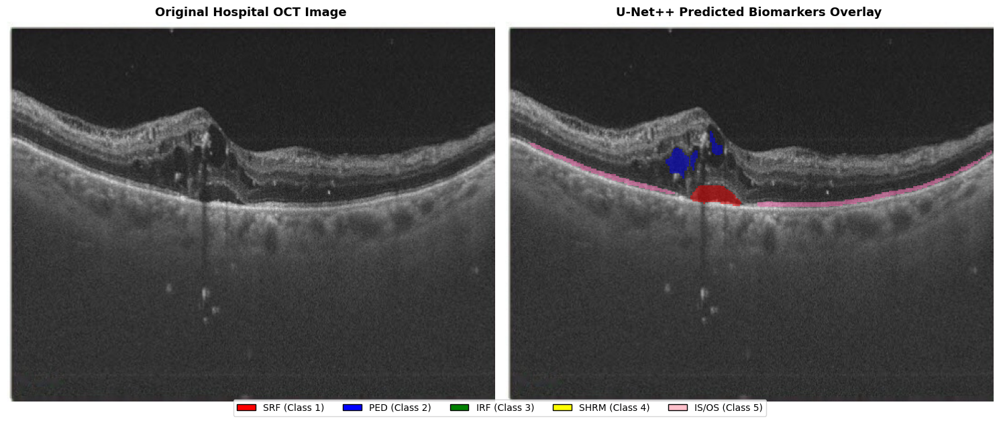

In [13]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Prepare the validation transform matching training preprocessing
val_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
    ToTensorV2()
])

# Load the uploaded image
original_image_np = np.array(original_image)
orig_h, orig_w = original_image_np.shape[:2]

# Preprocess
transformed = val_transform(image=original_image_np)
input_tensor = transformed["image"].unsqueeze(0).to(device)

# Run inference
unetpp_model.eval()
with torch.no_grad():
    logits = unetpp_model(input_tensor)
    pred_small = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)

# Resize mask back to original size
unetpp_mask = np.array(
    Image.fromarray(pred_small).resize((orig_w, orig_h), Image.Resampling.NEAREST)
)

# Setup custom colors matching AMD-SD
biomarker_names = ["Background", "SRF", "PED", "IRF", "SHRM", "IS/OS"]
biomarker_colors = ["black", "red", "blue", "green", "yellow", "pink"]

overlay_cmap = ListedColormap([
    (0, 0, 0, 0),      # Background: transparent
    (1, 0, 0, 1),      # SRF: red
    (0, 0, 1, 1),      # PED: blue
    (0, 0.65, 0, 1),   # IRF: green
    (1, 1, 0, 1),      # SHRM: yellow
    (1, 0.4, 0.7, 1)   # IS/OS: pink
])

# Plot original vs overlay
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].imshow(original_image_np)
axes[0].set_title("Original Hospital OCT Image", fontsize=13, fontweight="bold")
axes[0].axis("off")

# Overlay plot
axes[1].imshow(original_image_np)
visible_mask = np.ma.masked_where(unetpp_mask == 0, unetpp_mask)
axes[1].imshow(
    visible_mask,
    cmap=overlay_cmap,
    vmin=0,
    vmax=5,
    alpha=0.48,
    interpolation="nearest"
)
axes[1].set_title("U-Net++ Predicted Biomarkers Overlay", fontsize=13, fontweight="bold")
axes[1].axis("off")

# Legend configuration
legend_handles = [
    Patch(facecolor=biomarker_colors[i], edgecolor="black", label=f"{biomarker_names[i]} (Class {i})")
    for i in range(1, 6)
]
fig.legend(handles=legend_handles, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02), frameon=True)

plt.tight_layout()
plt.show()

In [14]:
def predict_mask(model, input_tensor, target_shape):
    model.eval()
    with torch.no_grad():
        logits = model(input_tensor)
        pred_small = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
    # Resize mask back to target shape (height, width)
    pred_resized = np.array(
        Image.fromarray(pred_small).resize((target_shape[1], target_shape[0]), Image.Resampling.NEAREST)
    )
    return pred_resized

# Run prediction on both models using correct variable names
unetpp_mask = predict_mask(
    unetpp_model, input_tensor, original_image_np.shape[:2]
)

deep_unet_mask = predict_mask(
    deep_unet, input_tensor, original_image_np.shape[:2]
)

print("Predictions completed successfully!")
print("U-Net++ unique classes found:", np.unique(unetpp_mask))
print("Deep U-Net unique classes found:", np.unique(deep_unet_mask))

Predictions completed successfully!
U-Net++ unique classes found: [0 1 2 5]
Deep U-Net unique classes found: [0 1 2 3 4 5]


In [15]:

import os
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Define the original Deep U-Net architecture
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class DeepUNet(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)
        self.enc5 = ConvBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Decoder
        self.up4 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(64, 32)

        self.final = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        e5 = self.enc5(self.pool(e4))

        d4 = self.up4(e5)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.final(d1)


# 2. Load the saved checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/AMD_Segmentation_Models/best_deep_unet.pth"
)

if not os.path.isfile(checkpoint_path):
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}"
    )

deep_unet_model = DeepUNet(num_classes=6).to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Your notebook saved the raw state_dict.
# These checks also support wrapped checkpoints.
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]

checkpoint = {
    key.removeprefix("module."): value
    for key, value in checkpoint.items()
}

deep_unet_model.load_state_dict(checkpoint, strict=True)
deep_unet_model.eval()

print("Deep U-Net model loaded successfully!")


Deep U-Net model loaded successfully!


In [16]:
deep_unet_mask = predict_mask(
    deep_unet_model,
    input_tensor,
    original_np.shape[:2]
)

deep_unet_overlay, deep_unet_colored = create_overlay(
    original_np,
    deep_unet_mask
)

Saving 11492172_871195_20230817_115048_OCTReport_L_001_OCT_07_clean.jpg to 11492172_871195_20230817_115048_OCTReport_L_001_OCT_07_clean (2).jpg
Uploaded image: 11492172_871195_20230817_115048_OCTReport_L_001_OCT_07_clean (2).jpg
Image size: (535, 416)


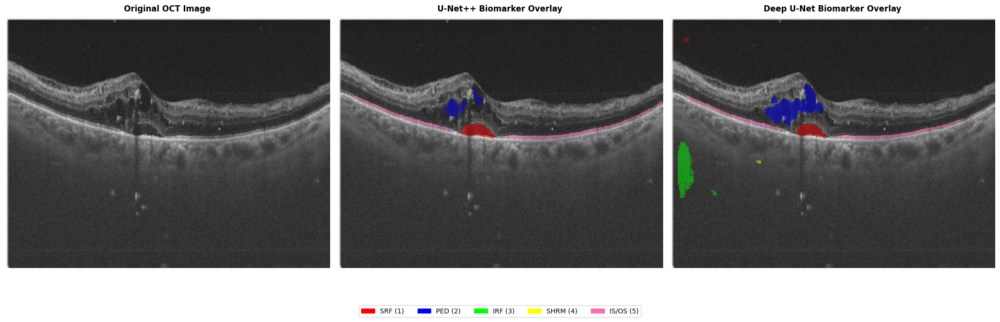


U-Net++ — predicted class distribution
SRF: 0.390% of image pixels
PED: 0.369% of image pixels
IRF: 0.000% of image pixels
SHRM: 0.000% of image pixels
IS/OS: 0.902% of image pixels

Deep U-Net — predicted class distribution
SRF: 0.358% of image pixels
PED: 1.250% of image pixels
IRF: 0.776% of image pixels
SHRM: 0.015% of image pixels
IS/OS: 0.826% of image pixels



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

import io
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from google.colab import files

# ==========================================
# 1. UPLOAD ONE OCT IMAGE
# ==========================================
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

image_name = next(iter(uploaded))
original_image = Image.open(
    io.BytesIO(uploaded[image_name])
).convert("RGB")

original_np = np.array(original_image)

print("Uploaded image:", image_name)
print("Image size:", original_image.size)

# ==========================================
# 2. PREPROCESS IMAGE
# Uses the transform defined earlier
# ==========================================
if "val_transform" in globals():
    transform_to_use = val_transform
elif "transform" in globals():
    transform_to_use = transform
else:
    raise NameError(
        "Define your original validation transform first."
    )

input_tensor = transform_to_use(
    image=original_np
)["image"].unsqueeze(0).to(device)

# ==========================================
# 3. PREDICT USING BOTH MODELS
# ==========================================
unetpp_model.eval()
deep_unet_model.eval()

with torch.no_grad():
    output_unetpp = unetpp_model(input_tensor)
    output_deep = deep_unet_model(input_tensor)

    # Handle models returning a tuple/list
    if isinstance(output_unetpp, (tuple, list)):
        output_unetpp = output_unetpp[0]
    if isinstance(output_deep, (tuple, list)):
        output_deep = output_deep[0]

    unetpp_mask = torch.argmax(
        output_unetpp, dim=1
    )[0].cpu().numpy().astype(np.uint8)

    deep_unet_mask = torch.argmax(
        output_deep, dim=1
    )[0].cpu().numpy().astype(np.uint8)

# Resize masks to original image dimensions
# Nearest-neighbor preserves class IDs
target_size = (original_image.width, original_image.height)

unetpp_mask = np.array(
    Image.fromarray(unetpp_mask).resize(
        target_size, Image.Resampling.NEAREST
    )
)

deep_unet_mask = np.array(
    Image.fromarray(deep_unet_mask).resize(
        target_size, Image.Resampling.NEAREST
    )
)

# ==========================================
# 4. BIOMARKER COLORS
# ==========================================
class_names = {
    0: "Background",
    1: "SRF",
    2: "PED",
    3: "IRF",
    4: "SHRM",
    5: "IS/OS"
}

class_colors = {
    0: (0, 0, 0),
    1: (255, 0, 0),       # SRF - Red
    2: (0, 0, 255),       # PED - Blue
    3: (0, 255, 0),       # IRF - Green
    4: (255, 255, 0),     # SHRM - Yellow
    5: (255, 105, 180)    # IS/OS - Pink
}

def make_overlay(image, mask, alpha=0.48):
    color_mask = np.zeros_like(image, dtype=np.uint8)

    for class_id, color in class_colors.items():
        if class_id != 0:
            color_mask[mask == class_id] = color

    overlay = image.copy()
    selected = mask != 0

    overlay[selected] = (
        (1 - alpha) * image[selected].astype(float)
        + alpha * color_mask[selected].astype(float)
    ).clip(0, 255).astype(np.uint8)

    return overlay, color_mask

unetpp_overlay, unetpp_colored = make_overlay(
    original_np, unetpp_mask
)

deep_unet_overlay, deep_unet_colored = make_overlay(
    original_np, deep_unet_mask
)

# ==========================================
# 5. DISPLAY RESULTS + LEGEND
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

axes[0].imshow(original_np)
axes[0].set_title("Original OCT Image", fontweight="bold")

axes[1].imshow(unetpp_overlay)
axes[1].set_title("U-Net++ Biomarker Overlay", fontweight="bold")

axes[2].imshow(deep_unet_overlay)
axes[2].set_title("Deep U-Net Biomarker Overlay", fontweight="bold")

for ax in axes:
    ax.axis("off")

legend_handles = [
    mpatches.Patch(
        color=np.array(class_colors[i]) / 255,
        label=f"{class_names[i]} ({i})"
    )
    for i in range(1, 6)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    bbox_to_anchor=(0.5, 0.01),
    frameon=True
)

plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

# ==========================================
# 6. REPORT PREDICTED BIOMARKERS
# ==========================================
def print_predictions(mask, model_name):
    print(f"\n{model_name} — predicted class distribution")

    total_pixels = mask.size

    for class_id in range(1, 6):
        pixels = int(np.sum(mask == class_id))
        percentage = pixels / total_pixels * 100

        print(
            f"{class_names[class_id]}: "
            f"{percentage:.3f}% of image pixels"
        )

print_predictions(unetpp_mask, "U-Net++")
print_predictions(deep_unet_mask, "Deep U-Net")

# ==========================================
# 7. SAVE AND DOWNLOAD OVERLAYS
# ==========================================
Image.fromarray(unetpp_overlay).save(
    "unetpp_biomarker_overlay.png"
)

Image.fromarray(deep_unet_overlay).save(
    "deep_unet_biomarker_overlay.png"
)

Image.fromarray(unetpp_mask).save(
    "unetpp_class_mask.png"
)

Image.fromarray(deep_unet_mask).save(
    "deep_unet_class_mask.png"
)

print("\nDownloading prediction images...")

files.download("unetpp_biomarker_overlay.png")
files.download("deep_unet_biomarker_overlay.png")
files.download("unetpp_class_mask.png")
files.download("deep_unet_class_mask.png")


Saving 17205153_897991_20250317_105234_OCTReport_R_001 - Copy_OCT_07_clean.jpg to 17205153_897991_20250317_105234_OCTReport_R_001 - Copy_OCT_07_clean.jpg
Uploaded image: 17205153_897991_20250317_105234_OCTReport_R_001 - Copy_OCT_07_clean.jpg
Image size: (535, 416)


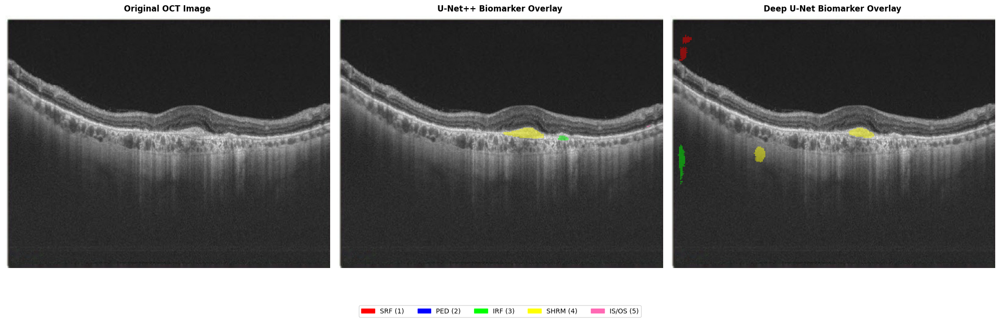


U-Net++ — predicted class distribution
SRF: 0.000% of image pixels
PED: 0.000% of image pixels
IRF: 0.051% of image pixels
SHRM: 0.346% of image pixels
IS/OS: 0.005% of image pixels

Deep U-Net — predicted class distribution
SRF: 0.157% of image pixels
PED: 0.000% of image pixels
IRF: 0.183% of image pixels
SHRM: 0.381% of image pixels
IS/OS: 0.000% of image pixels



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

import io
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from google.colab import files

# ==========================================
# 1. UPLOAD ONE OCT IMAGE
# ==========================================
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

image_name = next(iter(uploaded))
original_image = Image.open(
    io.BytesIO(uploaded[image_name])
).convert("RGB")

original_np = np.array(original_image)

print("Uploaded image:", image_name)
print("Image size:", original_image.size)

# ==========================================
# 2. PREPROCESS IMAGE
# Uses the transform defined earlier
# ==========================================
if "val_transform" in globals():
    transform_to_use = val_transform
elif "transform" in globals():
    transform_to_use = transform
else:
    raise NameError(
        "Define your original validation transform first."
    )

input_tensor = transform_to_use(
    image=original_np
)["image"].unsqueeze(0).to(device)

# ==========================================
# 3. PREDICT USING BOTH MODELS
# ==========================================
unetpp_model.eval()
deep_unet_model.eval()

with torch.no_grad():
    output_unetpp = unetpp_model(input_tensor)
    output_deep = deep_unet_model(input_tensor)

    # Handle models returning a tuple/list
    if isinstance(output_unetpp, (tuple, list)):
        output_unetpp = output_unetpp[0]
    if isinstance(output_deep, (tuple, list)):
        output_deep = output_deep[0]

    unetpp_mask = torch.argmax(
        output_unetpp, dim=1
    )[0].cpu().numpy().astype(np.uint8)

    deep_unet_mask = torch.argmax(
        output_deep, dim=1
    )[0].cpu().numpy().astype(np.uint8)

# Resize masks to original image dimensions
# Nearest-neighbor preserves class IDs
target_size = (original_image.width, original_image.height)

unetpp_mask = np.array(
    Image.fromarray(unetpp_mask).resize(
        target_size, Image.Resampling.NEAREST
    )
)

deep_unet_mask = np.array(
    Image.fromarray(deep_unet_mask).resize(
        target_size, Image.Resampling.NEAREST
    )
)

# ==========================================
# 4. BIOMARKER COLORS
# ==========================================
class_names = {
    0: "Background",
    1: "SRF",
    2: "PED",
    3: "IRF",
    4: "SHRM",
    5: "IS/OS"
}

class_colors = {
    0: (0, 0, 0),
    1: (255, 0, 0),       # SRF - Red
    2: (0, 0, 255),       # PED - Blue
    3: (0, 255, 0),       # IRF - Green
    4: (255, 255, 0),     # SHRM - Yellow
    5: (255, 105, 180)    # IS/OS - Pink
}

def make_overlay(image, mask, alpha=0.48):
    color_mask = np.zeros_like(image, dtype=np.uint8)

    for class_id, color in class_colors.items():
        if class_id != 0:
            color_mask[mask == class_id] = color

    overlay = image.copy()
    selected = mask != 0

    overlay[selected] = (
        (1 - alpha) * image[selected].astype(float)
        + alpha * color_mask[selected].astype(float)
    ).clip(0, 255).astype(np.uint8)

    return overlay, color_mask

unetpp_overlay, unetpp_colored = make_overlay(
    original_np, unetpp_mask
)

deep_unet_overlay, deep_unet_colored = make_overlay(
    original_np, deep_unet_mask
)

# ==========================================
# 5. DISPLAY RESULTS + LEGEND
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

axes[0].imshow(original_np)
axes[0].set_title("Original OCT Image", fontweight="bold")

axes[1].imshow(unetpp_overlay)
axes[1].set_title("U-Net++ Biomarker Overlay", fontweight="bold")

axes[2].imshow(deep_unet_overlay)
axes[2].set_title("Deep U-Net Biomarker Overlay", fontweight="bold")

for ax in axes:
    ax.axis("off")

legend_handles = [
    mpatches.Patch(
        color=np.array(class_colors[i]) / 255,
        label=f"{class_names[i]} ({i})"
    )
    for i in range(1, 6)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    bbox_to_anchor=(0.5, 0.01),
    frameon=True
)

plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

# ==========================================
# 6. REPORT PREDICTED BIOMARKERS
# ==========================================
def print_predictions(mask, model_name):
    print(f"\n{model_name} — predicted class distribution")

    total_pixels = mask.size

    for class_id in range(1, 6):
        pixels = int(np.sum(mask == class_id))
        percentage = pixels / total_pixels * 100

        print(
            f"{class_names[class_id]}: "
            f"{percentage:.3f}% of image pixels"
        )

print_predictions(unetpp_mask, "U-Net++")
print_predictions(deep_unet_mask, "Deep U-Net")

# ==========================================
# 7. SAVE AND DOWNLOAD OVERLAYS
# ==========================================
Image.fromarray(unetpp_overlay).save(
    "unetpp_biomarker_overlay.png"
)

Image.fromarray(deep_unet_overlay).save(
    "deep_unet_biomarker_overlay.png"
)

Image.fromarray(unetpp_mask).save(
    "unetpp_class_mask.png"
)

Image.fromarray(deep_unet_mask).save(
    "deep_unet_class_mask.png"
)

print("\nDownloading prediction images...")

files.download("unetpp_biomarker_overlay.png")
files.download("deep_unet_biomarker_overlay.png")
files.download("unetpp_class_mask.png")
files.download("deep_unet_class_mask.png")


Saving 19037956_787035_20201207_110254_OCTReport_R_001_OCT_01_clean.jpg to 19037956_787035_20201207_110254_OCTReport_R_001_OCT_01_clean.jpg
Uploaded image: 19037956_787035_20201207_110254_OCTReport_R_001_OCT_01_clean.jpg
Image size: (535, 416)


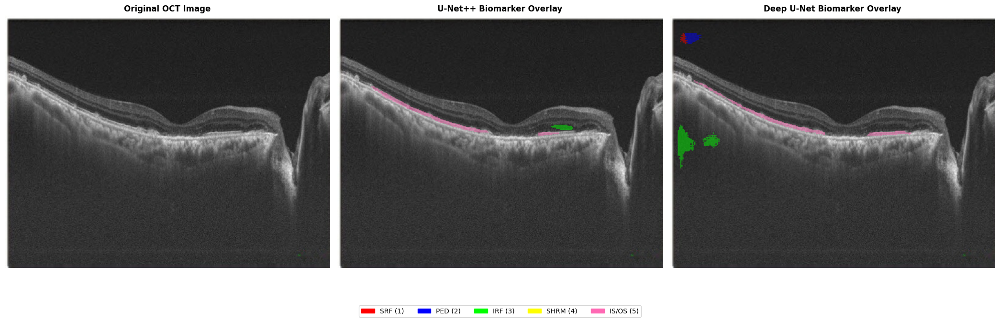


U-Net++ — predicted class distribution
SRF: 0.000% of image pixels
PED: 0.000% of image pixels
IRF: 0.109% of image pixels
SHRM: 0.000% of image pixels
IS/OS: 0.564% of image pixels

Deep U-Net — predicted class distribution
SRF: 0.049% of image pixels
PED: 0.151% of image pixels
IRF: 0.587% of image pixels
SHRM: 0.000% of image pixels
IS/OS: 0.628% of image pixels



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:

import io
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from google.colab import files

# ==========================================
# 1. UPLOAD ONE OCT IMAGE
# ==========================================
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

image_name = next(iter(uploaded))
original_image = Image.open(
    io.BytesIO(uploaded[image_name])
).convert("RGB")

original_np = np.array(original_image)

print("Uploaded image:", image_name)
print("Image size:", original_image.size)

# ==========================================
# 2. PREPROCESS IMAGE
# Uses the transform defined earlier
# ==========================================
if "val_transform" in globals():
    transform_to_use = val_transform
elif "transform" in globals():
    transform_to_use = transform
else:
    raise NameError(
        "Define your original validation transform first."
    )

input_tensor = transform_to_use(
    image=original_np
)["image"].unsqueeze(0).to(device)

# ==========================================
# 3. PREDICT USING BOTH MODELS
# ==========================================
unetpp_model.eval()
deep_unet_model.eval()

with torch.no_grad():
    output_unetpp = unetpp_model(input_tensor)
    output_deep = deep_unet_model(input_tensor)

    # Handle models returning a tuple/list
    if isinstance(output_unetpp, (tuple, list)):
        output_unetpp = output_unetpp[0]
    if isinstance(output_deep, (tuple, list)):
        output_deep = output_deep[0]

    unetpp_mask = torch.argmax(
        output_unetpp, dim=1
    )[0].cpu().numpy().astype(np.uint8)

    deep_unet_mask = torch.argmax(
        output_deep, dim=1
    )[0].cpu().numpy().astype(np.uint8)

# Resize masks to original image dimensions
# Nearest-neighbor preserves class IDs
target_size = (original_image.width, original_image.height)

unetpp_mask = np.array(
    Image.fromarray(unetpp_mask).resize(
        target_size, Image.Resampling.NEAREST
    )
)

deep_unet_mask = np.array(
    Image.fromarray(deep_unet_mask).resize(
        target_size, Image.Resampling.NEAREST
    )
)

# ==========================================
# 4. BIOMARKER COLORS
# ==========================================
class_names = {
    0: "Background",
    1: "SRF",
    2: "PED",
    3: "IRF",
    4: "SHRM",
    5: "IS/OS"
}

class_colors = {
    0: (0, 0, 0),
    1: (255, 0, 0),       # SRF - Red
    2: (0, 0, 255),       # PED - Blue
    3: (0, 255, 0),       # IRF - Green
    4: (255, 255, 0),     # SHRM - Yellow
    5: (255, 105, 180)    # IS/OS - Pink
}

def make_overlay(image, mask, alpha=0.48):
    color_mask = np.zeros_like(image, dtype=np.uint8)

    for class_id, color in class_colors.items():
        if class_id != 0:
            color_mask[mask == class_id] = color

    overlay = image.copy()
    selected = mask != 0

    overlay[selected] = (
        (1 - alpha) * image[selected].astype(float)
        + alpha * color_mask[selected].astype(float)
    ).clip(0, 255).astype(np.uint8)

    return overlay, color_mask

unetpp_overlay, unetpp_colored = make_overlay(
    original_np, unetpp_mask
)

deep_unet_overlay, deep_unet_colored = make_overlay(
    original_np, deep_unet_mask
)

# ==========================================
# 5. DISPLAY RESULTS + LEGEND
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

axes[0].imshow(original_np)
axes[0].set_title("Original OCT Image", fontweight="bold")

axes[1].imshow(unetpp_overlay)
axes[1].set_title("U-Net++ Biomarker Overlay", fontweight="bold")

axes[2].imshow(deep_unet_overlay)
axes[2].set_title("Deep U-Net Biomarker Overlay", fontweight="bold")

for ax in axes:
    ax.axis("off")

legend_handles = [
    mpatches.Patch(
        color=np.array(class_colors[i]) / 255,
        label=f"{class_names[i]} ({i})"
    )
    for i in range(1, 6)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    bbox_to_anchor=(0.5, 0.01),
    frameon=True
)

plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

# ==========================================
# 6. REPORT PREDICTED BIOMARKERS
# ==========================================
def print_predictions(mask, model_name):
    print(f"\n{model_name} — predicted class distribution")

    total_pixels = mask.size

    for class_id in range(1, 6):
        pixels = int(np.sum(mask == class_id))
        percentage = pixels / total_pixels * 100

        print(
            f"{class_names[class_id]}: "
            f"{percentage:.3f}% of image pixels"
        )

print_predictions(unetpp_mask, "U-Net++")
print_predictions(deep_unet_mask, "Deep U-Net")

# ==========================================
# 7. SAVE AND DOWNLOAD OVERLAYS
# ==========================================
Image.fromarray(unetpp_overlay).save(
    "unetpp_biomarker_overlay.png"
)

Image.fromarray(deep_unet_overlay).save(
    "deep_unet_biomarker_overlay.png"
)

Image.fromarray(unetpp_mask).save(
    "unetpp_class_mask.png"
)

Image.fromarray(deep_unet_mask).save(
    "deep_unet_class_mask.png"
)

print("\nDownloading prediction images...")

files.download("unetpp_biomarker_overlay.png")
files.download("deep_unet_biomarker_overlay.png")
files.download("unetpp_class_mask.png")
files.download("deep_unet_class_mask.png")


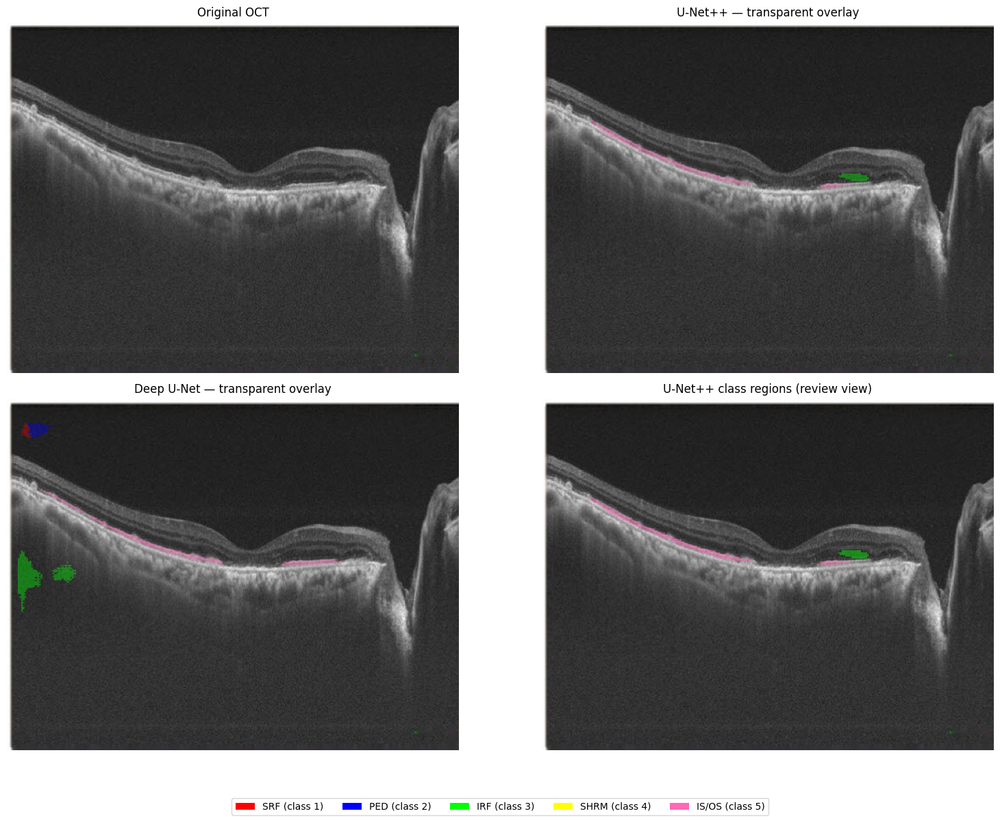


U-Net++ — predicted area and review flags
SRF: 0.0000% (0 pixels)
PED: 0.0000% (0 pixels)
IRF: 0.1087% (242 pixels)
SHRM: 0.0000% (0 pixels)
IS/OS: 0.5643% (1,256 pixels)

Deep U-Net — predicted area and review flags
SRF: 0.0494% (110 pixels)
PED: 0.1510% (336 pixels)
IRF: 0.5868% (1,306 pixels)
SHRM: 0.0000% (0 pixels)
IS/OS: 0.6281% (1,398 pixels)


In [20]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import ndimage

# Uses the existing variables:
# original_np, unetpp_mask, deep_unet_mask

CLASS_NAMES = {
    1: "SRF",
    2: "PED",
    3: "IRF",
    4: "SHRM",
    5: "IS/OS"
}

COLORS = {
    1: (1.0, 0.0, 0.0),       # SRF - red
    2: (0.0, 0.0, 1.0),       # PED - blue
    3: (0.0, 1.0, 0.0),       # IRF - green
    4: (1.0, 1.0, 0.0),       # SHRM - yellow
    5: (1.0, 0.41, 0.71)      # IS/OS - pink
}

def resize_label_mask(mask, height, width):
    """Resize categorical labels without inventing new class IDs."""
    from PIL import Image
    return np.asarray(
        Image.fromarray(mask.astype(np.uint8)).resize(
            (width, height), Image.Resampling.NEAREST
        )
    )

def make_clinical_review_overlay(image, mask, alpha=0.38):
    """Create transparent class fills and class-boundary contours."""
    h, w = image.shape[:2]
    mask = resize_label_mask(mask, h, w)

    overlay = image.astype(np.float32).copy() / 255.0
    boundary_image = image.copy()

    for class_id, color in COLORS.items():
        region = (mask == class_id)

        # Transparent fill
        overlay[region] = (
            (1 - alpha) * overlay[region]
            + alpha * np.array(color)
        )

        # Boundary pixels: region minus its eroded interior
        if np.any(region):
            eroded = ndimage.binary_erosion(
                region, structure=np.ones((3, 3)), iterations=1
            )
            boundary = region & ~eroded
            boundary_image[boundary] = (
                np.array(color) * 255
            ).astype(np.uint8)

    overlay = (np.clip(overlay, 0, 1) * 255).astype(np.uint8)
    return overlay, boundary_image, mask

def summarize_prediction(mask, model_name):
    total = mask.size
    print(f"\n{model_name} — predicted area and review flags")

    for class_id, name in CLASS_NAMES.items():
        region = mask == class_id
        pixels = int(region.sum())
        pct = 100 * pixels / total

        # A heuristic review flag, not a clinical threshold
        flag = ""
        if pct > 10:
            flag = "  <-- REVIEW: unusually large predicted area"
        elif pixels > 0 and pct < 0.001:
            flag = "  <-- REVIEW: very small predicted region"

        print(f"{name}: {pct:.4f}% ({pixels:,} pixels){flag}")

    if not np.isin(mask, [0, 1, 2, 3, 4, 5]).all():
        print("WARNING: unexpected class IDs found.")

# Prepare overlays
u_overlay, u_boundary, u_mask = make_clinical_review_overlay(
    original_np, unetpp_mask
)
d_overlay, d_boundary, d_mask = make_clinical_review_overlay(
    original_np, deep_unet_mask
)

# Display four views per model for easier review
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0, 0].imshow(original_np)
axes[0, 0].set_title("Original OCT")

axes[0, 1].imshow(u_overlay)
axes[0, 1].set_title("U-Net++ — transparent overlay")

axes[1, 0].imshow(d_overlay)
axes[1, 0].set_title("Deep U-Net — transparent overlay")

# Compare model boundaries directly on the OCT
axes[1, 1].imshow(original_np)
axes[1, 1].imshow(
    np.ma.masked_where(u_mask == 0, u_mask),
    alpha=0.45,
    interpolation="nearest",
    cmap=plt.matplotlib.colors.ListedColormap(
        ["red", "blue", "lime", "yellow", "hotpink"]
    ),
    vmin=1, vmax=5
)
axes[1, 1].set_title("U-Net++ class regions (review view)")

for ax in axes.flat:
    ax.axis("off")

handles = [
    Patch(facecolor=COLORS[i], label=f"{CLASS_NAMES[i]} (class {i})")
    for i in CLASS_NAMES
]
fig.legend(handles=handles, loc="lower center", ncol=5)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

summarize_prediction(u_mask, "U-Net++")
summarize_prediction(d_mask, "Deep U-Net")


Saving 22913219_871195_20231107_135908_OCTReport_R_001_OCT_07_clean.jpg to 22913219_871195_20231107_135908_OCTReport_R_001_OCT_07_clean.jpg
Uploaded image: 22913219_871195_20231107_135908_OCTReport_R_001_OCT_07_clean.jpg
Image size: (535, 416)


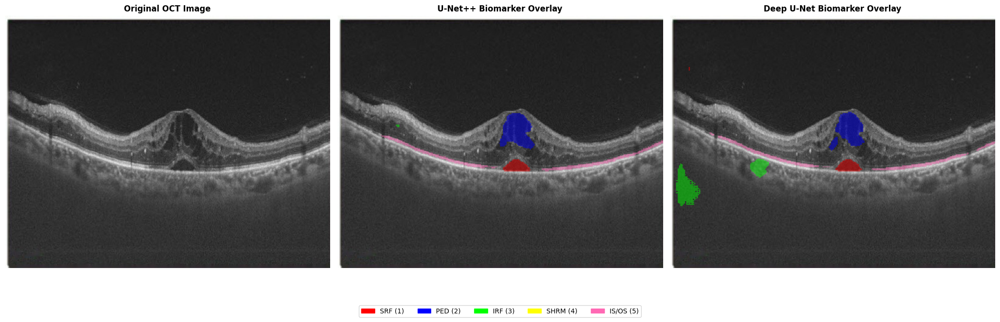


U-Net++ — predicted class distribution
SRF: 0.287% of image pixels
PED: 1.009% of image pixels
IRF: 0.009% of image pixels
SHRM: 0.000% of image pixels
IS/OS: 0.842% of image pixels

Deep U-Net — predicted class distribution
SRF: 0.284% of image pixels
PED: 0.895% of image pixels
IRF: 0.989% of image pixels
SHRM: 0.000% of image pixels
IS/OS: 0.779% of image pixels



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:

import io
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from google.colab import files

# ==========================================
# 1. UPLOAD ONE OCT IMAGE
# ==========================================
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

image_name = next(iter(uploaded))
original_image = Image.open(
    io.BytesIO(uploaded[image_name])
).convert("RGB")

original_np = np.array(original_image)

print("Uploaded image:", image_name)
print("Image size:", original_image.size)

# ==========================================
# 2. PREPROCESS IMAGE
# Uses the transform defined earlier
# ==========================================
if "val_transform" in globals():
    transform_to_use = val_transform
elif "transform" in globals():
    transform_to_use = transform
else:
    raise NameError(
        "Define your original validation transform first."
    )

input_tensor = transform_to_use(
    image=original_np
)["image"].unsqueeze(0).to(device)

# ==========================================
# 3. PREDICT USING BOTH MODELS
# ==========================================
unetpp_model.eval()
deep_unet_model.eval()

with torch.no_grad():
    output_unetpp = unetpp_model(input_tensor)
    output_deep = deep_unet_model(input_tensor)

    # Handle models returning a tuple/list
    if isinstance(output_unetpp, (tuple, list)):
        output_unetpp = output_unetpp[0]
    if isinstance(output_deep, (tuple, list)):
        output_deep = output_deep[0]

    unetpp_mask = torch.argmax(
        output_unetpp, dim=1
    )[0].cpu().numpy().astype(np.uint8)

    deep_unet_mask = torch.argmax(
        output_deep, dim=1
    )[0].cpu().numpy().astype(np.uint8)

# Resize masks to original image dimensions
# Nearest-neighbor preserves class IDs
target_size = (original_image.width, original_image.height)

unetpp_mask = np.array(
    Image.fromarray(unetpp_mask).resize(
        target_size, Image.Resampling.NEAREST
    )
)

deep_unet_mask = np.array(
    Image.fromarray(deep_unet_mask).resize(
        target_size, Image.Resampling.NEAREST
    )
)

# ==========================================
# 4. BIOMARKER COLORS
# ==========================================
class_names = {
    0: "Background",
    1: "SRF",
    2: "PED",
    3: "IRF",
    4: "SHRM",
    5: "IS/OS"
}

class_colors = {
    0: (0, 0, 0),
    1: (255, 0, 0),       # SRF - Red
    2: (0, 0, 255),       # PED - Blue
    3: (0, 255, 0),       # IRF - Green
    4: (255, 255, 0),     # SHRM - Yellow
    5: (255, 105, 180)    # IS/OS - Pink
}

def make_overlay(image, mask, alpha=0.48):
    color_mask = np.zeros_like(image, dtype=np.uint8)

    for class_id, color in class_colors.items():
        if class_id != 0:
            color_mask[mask == class_id] = color

    overlay = image.copy()
    selected = mask != 0

    overlay[selected] = (
        (1 - alpha) * image[selected].astype(float)
        + alpha * color_mask[selected].astype(float)
    ).clip(0, 255).astype(np.uint8)

    return overlay, color_mask

unetpp_overlay, unetpp_colored = make_overlay(
    original_np, unetpp_mask
)

deep_unet_overlay, deep_unet_colored = make_overlay(
    original_np, deep_unet_mask
)

# ==========================================
# 5. DISPLAY RESULTS + LEGEND
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

axes[0].imshow(original_np)
axes[0].set_title("Original OCT Image", fontweight="bold")

axes[1].imshow(unetpp_overlay)
axes[1].set_title("U-Net++ Biomarker Overlay", fontweight="bold")

axes[2].imshow(deep_unet_overlay)
axes[2].set_title("Deep U-Net Biomarker Overlay", fontweight="bold")

for ax in axes:
    ax.axis("off")

legend_handles = [
    mpatches.Patch(
        color=np.array(class_colors[i]) / 255,
        label=f"{class_names[i]} ({i})"
    )
    for i in range(1, 6)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    bbox_to_anchor=(0.5, 0.01),
    frameon=True
)

plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

# ==========================================
# 6. REPORT PREDICTED BIOMARKERS
# ==========================================
def print_predictions(mask, model_name):
    print(f"\n{model_name} — predicted class distribution")

    total_pixels = mask.size

    for class_id in range(1, 6):
        pixels = int(np.sum(mask == class_id))
        percentage = pixels / total_pixels * 100

        print(
            f"{class_names[class_id]}: "
            f"{percentage:.3f}% of image pixels"
        )

print_predictions(unetpp_mask, "U-Net++")
print_predictions(deep_unet_mask, "Deep U-Net")

# ==========================================
# 7. SAVE AND DOWNLOAD OVERLAYS
# ==========================================
Image.fromarray(unetpp_overlay).save(
    "unetpp_biomarker_overlay.png"
)

Image.fromarray(deep_unet_overlay).save(
    "deep_unet_biomarker_overlay.png"
)

Image.fromarray(unetpp_mask).save(
    "unetpp_class_mask.png"
)

Image.fromarray(deep_unet_mask).save(
    "deep_unet_class_mask.png"
)

print("\nDownloading prediction images...")

files.download("unetpp_biomarker_overlay.png")
files.download("deep_unet_biomarker_overlay.png")
files.download("unetpp_class_mask.png")
files.download("deep_unet_class_mask.png")


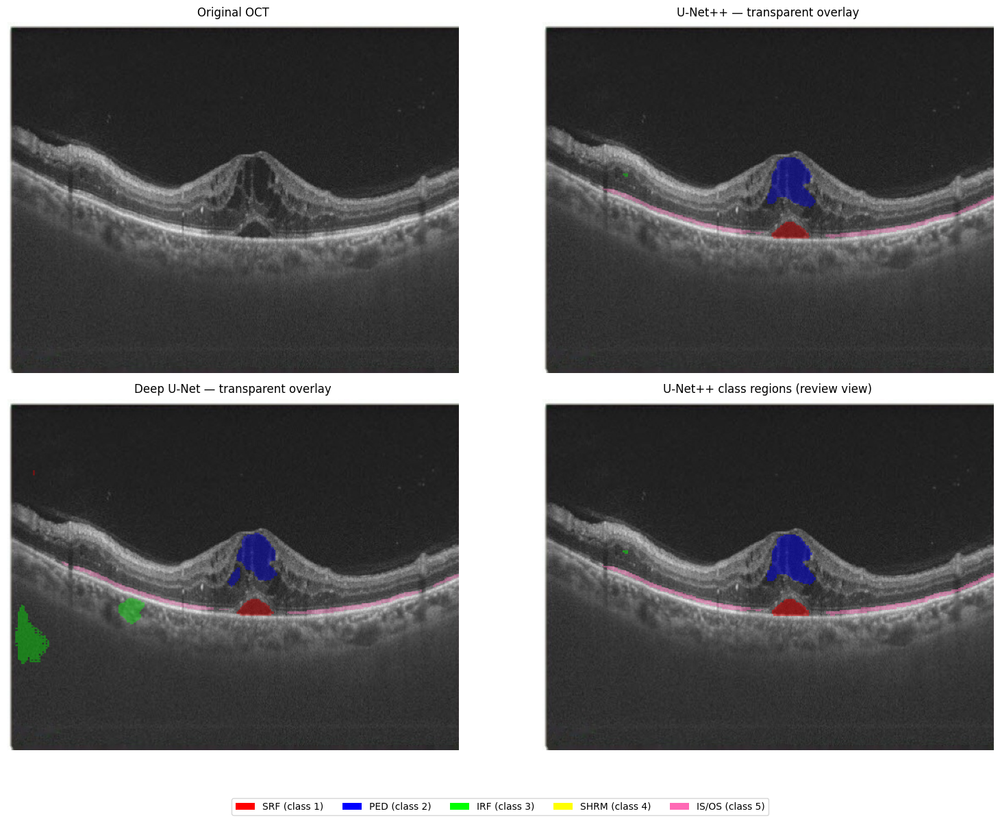


U-Net++ — predicted area and review flags
SRF: 0.2871% (639 pixels)
PED: 1.0087% (2,245 pixels)
IRF: 0.0090% (20 pixels)
SHRM: 0.0000% (0 pixels)
IS/OS: 0.8416% (1,873 pixels)

Deep U-Net — predicted area and review flags
SRF: 0.2835% (631 pixels)
PED: 0.8955% (1,993 pixels)
IRF: 0.9894% (2,202 pixels)
SHRM: 0.0000% (0 pixels)
IS/OS: 0.7787% (1,733 pixels)


In [22]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import ndimage

# Uses the existing variables:
# original_np, unetpp_mask, deep_unet_mask

CLASS_NAMES = {
    1: "SRF",
    2: "PED",
    3: "IRF",
    4: "SHRM",
    5: "IS/OS"
}

COLORS = {
    1: (1.0, 0.0, 0.0),       # SRF - red
    2: (0.0, 0.0, 1.0),       # PED - blue
    3: (0.0, 1.0, 0.0),       # IRF - green
    4: (1.0, 1.0, 0.0),       # SHRM - yellow
    5: (1.0, 0.41, 0.71)      # IS/OS - pink
}

def resize_label_mask(mask, height, width):
    """Resize categorical labels without inventing new class IDs."""
    from PIL import Image
    return np.asarray(
        Image.fromarray(mask.astype(np.uint8)).resize(
            (width, height), Image.Resampling.NEAREST
        )
    )

def make_clinical_review_overlay(image, mask, alpha=0.38):
    """Create transparent class fills and class-boundary contours."""
    h, w = image.shape[:2]
    mask = resize_label_mask(mask, h, w)

    overlay = image.astype(np.float32).copy() / 255.0
    boundary_image = image.copy()

    for class_id, color in COLORS.items():
        region = (mask == class_id)

        # Transparent fill
        overlay[region] = (
            (1 - alpha) * overlay[region]
            + alpha * np.array(color)
        )

        # Boundary pixels: region minus its eroded interior
        if np.any(region):
            eroded = ndimage.binary_erosion(
                region, structure=np.ones((3, 3)), iterations=1
            )
            boundary = region & ~eroded
            boundary_image[boundary] = (
                np.array(color) * 255
            ).astype(np.uint8)

    overlay = (np.clip(overlay, 0, 1) * 255).astype(np.uint8)
    return overlay, boundary_image, mask

def summarize_prediction(mask, model_name):
    total = mask.size
    print(f"\n{model_name} — predicted area and review flags")

    for class_id, name in CLASS_NAMES.items():
        region = mask == class_id
        pixels = int(region.sum())
        pct = 100 * pixels / total

        # A heuristic review flag, not a clinical threshold
        flag = ""
        if pct > 10:
            flag = "  <-- REVIEW: unusually large predicted area"
        elif pixels > 0 and pct < 0.001:
            flag = "  <-- REVIEW: very small predicted region"

        print(f"{name}: {pct:.4f}% ({pixels:,} pixels){flag}")

    if not np.isin(mask, [0, 1, 2, 3, 4, 5]).all():
        print("WARNING: unexpected class IDs found.")

# Prepare overlays
u_overlay, u_boundary, u_mask = make_clinical_review_overlay(
    original_np, unetpp_mask
)
d_overlay, d_boundary, d_mask = make_clinical_review_overlay(
    original_np, deep_unet_mask
)

# Display four views per model for easier review
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0, 0].imshow(original_np)
axes[0, 0].set_title("Original OCT")

axes[0, 1].imshow(u_overlay)
axes[0, 1].set_title("U-Net++ — transparent overlay")

axes[1, 0].imshow(d_overlay)
axes[1, 0].set_title("Deep U-Net — transparent overlay")

# Compare model boundaries directly on the OCT
axes[1, 1].imshow(original_np)
axes[1, 1].imshow(
    np.ma.masked_where(u_mask == 0, u_mask),
    alpha=0.45,
    interpolation="nearest",
    cmap=plt.matplotlib.colors.ListedColormap(
        ["red", "blue", "lime", "yellow", "hotpink"]
    ),
    vmin=1, vmax=5
)
axes[1, 1].set_title("U-Net++ class regions (review view)")

for ax in axes.flat:
    ax.axis("off")

handles = [
    Patch(facecolor=COLORS[i], label=f"{CLASS_NAMES[i]} (class {i})")
    for i in CLASS_NAMES
]
fig.legend(handles=handles, loc="lower center", ncol=5)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

summarize_prediction(u_mask, "U-Net++")
summarize_prediction(d_mask, "Deep U-Net")
